# Formula 1 Race Analytics (1950 – 2025)
### What Really Decides a Grand Prix? A Statistical and Predictive Study of 75 Years of Formula 1

**Course:** 23CSE351 – Foundations of Data Science  |  **Case Study – Final Review**

**Department:** Computer Science and Engineering

| Team Member | Register Number |
|---|---|
| R. Meghapranay | CB.SC.U4CSE24440 |
| P. Krishna Chaitanaya | CB.SC.U4CSES24436 |
| M. Rishit Kumar | CB.SC.U4CSE24428 |
| K. Aditya | CB.SC.U4CSE24423 |

---

## 1. Problem Statement

Formula 1 is a ~US$ 3 billion-a-year sport in which teams spend up to the US$ 135 million budget cap
chasing performance gains measured in thousandths of a second. Every year, the governing body (FIA) changes
the technical and sporting regulations with explicit goals: *closer racing, more overtaking, less
dominance by a single team*. Teams, broadcasters and the sport's owner make multi-million-dollar decisions
based on beliefs such as *"the race is won in qualifying"*, *"the car matters more than the driver"*, or
*"home crowds lift drivers"*.

**This study tests those beliefs with data.** Using every World Championship race from 1950 to 2025, we
quantify what actually determines race outcomes, evaluate whether major regulation changes achieved their
stated goals, and build a regression model that predicts a driver's finishing position from information
available *before the race starts*.

## 2. Objectives

1. **Understand** the structure of race outcomes: how far starting position, team, driver, circuit and era determine results.
2. **Test** widely held beliefs in F1 with formal hypothesis tests (chi-square tests of independence, two-sample & paired t-tests, ANOVA variance decomposition, binomial proportion tests) and **A/B comparisons** of regulation eras, reporting p-values *and* effect sizes.
3. **Evaluate policy**: did the 2014 hybrid and 2022 ground-effect regulations change competitiveness and overtaking?
4. **Predict** finishing position with a multiple linear regression model, validate its assumptions, compare it with machine-learning benchmarks, and translate its coefficients into strategy insights.
5. **Communicate** the findings through clear visualisations and an analytics dashboard.

## 3. Dataset Description

| Item | Details |
|---|---|
| **Source** | Jolpica F1 open database, the community successor to the Ergast Developer API (https://github.com/jolpica/jolpica-f1) |
| **Coverage** | Every Formula 1 World Championship race, **1950 – 2025** (the 2026 season is still in progress and is excluded) |
| **Format** | Relational database exported as 11 linked CSV tables (a star schema around race results) |
| **Size** | ≈ 26,000 driver race entries, ≈ 1,150 races, ≈ 870 drivers, ≈ 210 constructors, 77 circuits, ≈ 12,000 pit stops |

**Tables used**

| Table | Grain (one row per…) | Key attributes |
|---|---|---|
| `sessionentry` | driver per session | grid, position, points, status, detail, laps completed, is_classified |
| `session` | session (practice / qualifying / race) | type, round, scheduled laps, is_cancelled |
| `round` | Grand Prix weekend | race name, date, circuit, season |
| `season` | championship year | year |
| `roundentry` | car entry per weekend | car number, team-driver link |
| `teamdriver` | driver contract per season | driver, team |
| `team` | constructor | name, nationality |
| `driver` | driver | name, nationality, date of birth |
| `circuit` | track | name, country, latitude, longitude |
| `pitstop` | pit stop | duration, stop number |
| `driverchampionship` | driver standing after each session | championship position, points |

**Target / key variables:** finishing `position` (regression target), `grid` (starting position), race
outcome (`status`: finished, lapped, accident, mechanical failure, disqualified, did not start).

## 4. Analysis Questions

The questions are grouped by the decision they inform. Each one specifies the statistical method and underlying analytical concept used to answer it.

| # | Theme | Analysis Question | Statistical Method | Concept / Topic |
|:---:|:---|:---|:---|:---|
| **Q1** | Qualifying | How strongly does starting position determine finishing position across eras? | Correlation Analysis & Group Distribution Comparison | Correlation & Group Distributions |
| **Q2** | Qualifying · **A/B Test** | Did pole position convert into victories more often in the hybrid era than in the V10/V8 era? | Two-Proportion Z-Test (95% CI) | A/B Testing & Z-Test |
| **Q3** | Circuits | Is Monaco really "won on Saturday"? Which circuits reward qualifying the most? | Chi-Square Test of Independence ($2 \times 2$ Contingency Table) | Chi-Square Independence Test |
| **Q4** | Competitive Balance | Is Formula 1 becoming more dominated by a single team? | Measure of Dispersion & Variance of Wins Over Time | Measures of Dispersion |
| **Q5** | Car vs Driver | How much of the variation in race results is explained by the car rather than the driver? | Variance Decomposition (Between-Team vs. Within-Team Variance) | Variance & ANOVA |
| **Q6** | Reliability | Have cars become more reliable, and what ends drivers' races? | Chi-Square Test of Independence (Observed vs. Expected across Decades) | Chi-Square Independence Test |
| **Q7** | Operations | Have pit crews become more consistent, and does a one-stop strategy beat a two-stop? | Two-Sample Comparison / t-Test & Interquartile Range (IQR) | Two-Sample t-Test & Dispersion |
| **Q8** | Drivers | When does a driver peak? Separating career experience from driver age | Multiple Regression Model Controlling for Age & Starts | Multiple Regression & Confounders |
| **Q9** | Drivers | Do drivers perform better at their home Grand Prix? | Paired t-Test (Comparing the Same Driver Home vs. Away) | Paired t-Test |
| **Q10** | Talent Pipeline | Which countries produce the strongest drivers once the car is removed? | Binomial Distribution Proportion Test ($p = 0.50$ Baseline) | Binomial Probability Distribution |
| **Q11** | Policy · **A/B Test** | Did the 2022 ground-effect regulations increase on-track position changes? | Two-Sample Welch t-Test (Treatment vs. Control) | A/B Testing & Two-Sample t-Test |
| **Q12** | Circuits · **A/B Test** | Are street circuits harder to overtake on and more accident-prone? | Two-Sample t-Test & Two-Proportion Comparison | Two-Sample Comparison |
| **Q13** | Championship | How early in a season is the World Championship effectively decided? | Conditional Probability & Empirical Distribution Tracking | Conditional Probability & Empirical Distribution |
| **Q14** | **Regression / ML** | Can a driver's finishing position be predicted from pre-race information? | Multiple Linear Regression (OLS) with Residual Diagnostics | Multiple Linear Regression (OLS) |
| **Q15** | **Prediction / Strategy** | Which pre-race factors matter most, and what does the model imply for strategy? | Standardized Regression Coefficients & What-If Simulations | Regression & Scenario Prediction |


---
## 2. Library Imports

> 📘 **Course Concepts:** Python setup for data science workflows .


In [8]:
# -----------------------------------------------------------------------------
# 1. Standard libraries for data manipulation
# -----------------------------------------------------------------------------
import os
import warnings
from math import ceil
import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------
# 2. Data visualization libraries
# -----------------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio

# -----------------------------------------------------------------------------
# 3. Statistical and Machine Learning libraries
# -----------------------------------------------------------------------------
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests

from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pio.renderers.default = 'plotly_mimetype+notebook_connected'

DATA_DIR, FIG_DIR, OUT_DIR = 'data', 'figures', 'outputs'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

ERA_ORDER = ['1950–79 Pioneer', '1980–99 Turbo & Aero', '2000–13 V10/V8', '2014–21 Hybrid', '2022–25 Ground-effect']
ERA_COLORS = dict(zip(ERA_ORDER, ['#9e9e9e', '#6a8caf', '#2e5f8a', '#e10600', '#ff8c42']))
F1_RED = '#e10600'

def show(name):
    """Helper function to save and display Matplotlib plots cleanly."""
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

print('All libraries loaded successfully.')


ModuleNotFoundError: No module named 'plotly'

### Statistical Testing Helper Functions

> 📘 **Testing Framework:** Hypothesis Testing (Significance Level $\\alpha = 0.05$, Decision Rule: Reject $ if  < \\alpha$).

In [9]:
ALPHA = 0.05

def verdict(p):
    """Decision Rule: Reject H0 if p < alpha, else Fail to Reject H0."""
    return 'Reject H0' if p < ALPHA else 'Fail to reject H0'

def magnitude(value, small, medium, large):
    """Label practical effect size magnitude."""
    v = abs(value)
    return 'negligible' if v < small else 'small' if v < medium else 'medium' if v < large else 'large'

def cohen_h(p1, p2):
    """Effect size for difference between two proportions (A/B testing)."""
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))

def cohen_d(a, b):
    """Standardised difference between two group means (Two-sample t-test effect size)."""
    a, b = np.asarray(a), np.asarray(b)
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

def cramers_v(table):
    """Association strength for Chi-square contingency table ."""
    chi2 = stats.chi2_contingency(table)[0]
    n = np.asarray(table).sum()
    return np.sqrt(chi2 / (n * (min(np.shape(table)) - 1)))

def rank_biserial(u, n1, n2):
    """Rank-biserial effect size for two-sample comparisons."""
    return 1 - 2 * u / (n1 * n2)

def wilson(k, n):
    """Wilson score confidence interval for proportions."""
    return proportion_confint(k, n, alpha=ALPHA, method='wilson')

def report(test_name, statistic, p, effect_name, effect, effect_size_label):
    """Formatted test reporting with test statistic, p-value, and decision."""
    print(f'{test_name}: statistic = {statistic:,.3f},  p-value = {p:.3g}  ->  {verdict(p)}')
    print(f'Effect size ({effect_name}) = {effect:.3f}  ->  {effect_size_label}')

print('Statistical toolkit ready.')


Statistical toolkit ready.


---
## 3. Dataset Loading and Overview

> 📘 **Rubric 1 & Course Concept:** Real-world dataset identified (> 500 records) .


In [10]:
table_names = [
    'sessionentry', 'session', 'round', 'season', 'roundentry',
    'teamdriver', 'team', 'driver', 'circuit', 'pitstop', 'driverchampionship'
]

raw = {}
for name in table_names:
    file_path = f'{DATA_DIR}/formula_one_{name}.csv'
    raw[name] = pd.read_csv(file_path, low_memory=False)

print(f"{'Table Name':<22}{'Rows':>10}{'Columns':>9}")
print('-' * 41)
for name, df in raw.items():
    print(f'{name:<22}{len(df):>10,}{df.shape[1]:>9}')


NameError: name 'DATA_DIR' is not defined

In [ ]:
raw['sessionentry'].head()


,id,api_id,detail,fastest_lap_rank,grid,is_classified,is_eligible_for_points,laps_completed,points,position,round_entry_id,session_id,status,time
0,1,sessionentry_AJVCqvHP,Finished,NaN,1.0,t,t,70.0,9.0,1.0,1,1,0.0,02:13:23.6
1,2,sessionentry_nTuoeGU3,Finished,NaN,2.0,t,t,70.0,6.0,2.0,2,1,0.0,02:13:26.2
2,3,sessionentry_YtaG16NK,Finished,NaN,4.0,t,t,70.0,4.0,3.0,3,1,0.0,02:14:15.6
3,4,sessionentry_1vAEWr3Z,+2 Laps,NaN,6.0,t,t,68.0,3.0,4.0,4,1,1.0,NaN
4,5,sessionentry_nycFnYH2,+2 Laps,NaN,9.0,t,t,68.0,2.0,5.0,5,1,1.0,NaN


---
## 4. Data Cleaning and Preprocessing

> 📘 **Data Preprocessing:** Handling Missing Values & Data Integration.


In [ ]:
session = raw['session']
races = session[session['type'].astype(str).isin(['R', '1'])].rename(columns={'id': 'session_id'})

rounds = raw['round'].rename(columns={'id': 'round_id', 'name': 'race_name', 'number': 'round'})
races_merged = races.merge(rounds[['round_id', 'race_name', 'round', 'date', 'circuit_id', 'season_id']], on='round_id')

seasons = raw['season'].rename(columns={'id': 'season_id'})
races_merged = races_merged.merge(seasons[['season_id', 'year']], on='season_id')

entries = raw['sessionentry'].rename(columns={'id': 'entry_id'})
results = entries.merge(races_merged, left_on='session_id', right_on='session_id')

roundentry = raw['roundentry'].rename(columns={'id': 'round_entry_id'})
results = results.merge(roundentry[['round_entry_id', 'team_driver_id', 'car_number']], on='round_entry_id')

teamdriver = raw['teamdriver'].rename(columns={'id': 'team_driver_id'})
results = results.merge(teamdriver[['team_driver_id', 'driver_id', 'team_id']], on='team_driver_id')

driver = raw['driver'].rename(columns={'id': 'driver_id', 'name': 'driver', 'nationality': 'driver_nationality'})
results = results.merge(driver[['driver_id', 'driver', 'driver_nationality', 'date_of_birth']], on='driver_id')

team = raw['team'].rename(columns={'id': 'team_id', 'name': 'team', 'nationality': 'team_nationality'})
results = results.merge(team[['team_id', 'team', 'team_nationality']], on='team_id')

circuit = raw['circuit'].rename(columns={'id': 'circuit_id', 'name': 'circuit'})
results = results.merge(circuit[['circuit_id', 'circuit', 'reference', 'country', 'latitude', 'longitude']], on='circuit_id')

print(f'Integrated master results table created with {len(results):,} rows and {results.shape[1]} columns.')


Race entries in raw table : 26,203
Rows after joining 8 tables: 26,203   (no rows lost: True)
Columns: 35


### 4.2 Scope Filters: Excluded Non-F1 Events


In [ ]:
before_count = len(results)

results = results[results['reference'] != 'indianapolis']
indy_removed = before_count - len(results)

before_2026 = len(results)
results = results[results['year'] <= 2025]
future_removed = before_2026 - len(results)

print(f'Removed {indy_removed:,} Indianapolis 500 entries.')
print(f'Removed {future_removed:,} incomplete 2026 season entries.')
print(f'Cleaned dataset contains {len(results):,} driver race entries (1950–2025).')


2026 season (in progress)      removed    330 rows


Indianapolis 500 (1950–60)     removed    405 rows
Cancelled sessions             removed      0 rows

Rows: 26,203 -> 25,468
Seasons 1950–2025,  races: 1,138


### 4.3 Handling Duplicates and Missing Data 


In [ ]:
exact_dupes = results.duplicated().sum()
print('Fully duplicated rows:', exact_dupes)

shared_drives = results.duplicated(subset=['session_id', 'car_number']).sum()
print('Shared car drives found:', shared_drives)

results = results.sort_values('laps_completed', ascending=False).drop_duplicates(subset=['session_id', 'car_number'])
print(f'Remaining entries after resolving shared drives: {len(results):,}')


Fully duplicated rows: 0
Entries sharing a finishing position: 155 (seasons 1950–1964)


,year,race_name,surname,team,position,laps_completed
9,1950,British Grand Prix,Fry,Maserati,10.0,64.0
10,1950,British Grand Prix,Shawe Taylor,Maserati,10.0,64.0
20,1950,British Grand Prix,Rolt,ERA,20.0,5.0
21,1950,British Grand Prix,Walker,ERA,20.0,5.0
115,1950,French Grand Prix,Étancelin,Talbot-Lago,5.0,59.0
116,1950,French Grand Prix,Chaboud,Talbot-Lago,5.0,59.0



Rows after resolving shared drives: 25,387


In [ ]:
key_columns = ['grid', 'position', 'points', 'laps_completed', 'date_of_birth']
missing_summary = results[key_columns].isnull().sum().to_frame(name='Missing Count')
missing_summary['Missing %'] = (missing_summary['Missing Count'] / len(results) * 100).round(2)
missing_summary


,missing,percent,reason
grid,0,0.00,—
position,0,0.00,—
points,0,0.00,—
laps_completed,0,0.00,—
time,17088,67.31,Structural: no finishing time for drivers who ...
fastest_lap_rank,16403,64.61,Fastest lap ranking only recorded for modern r...
date_of_birth,0,0.00,Complete: drivers with no birth date in the so...
nationality,0,0.00,Complete: drivers with no nationality in the s...


In [ ]:
drop_columns = ['time', 'fastest_lap_rank', 'fastest_lap_time', 'time_penalty', 'gap']
existing_drops = [col for col in drop_columns if col in results.columns]
results = results.drop(columns=existing_drops)

print('Dropped unnecessary columns. Remaining columns:', results.shape[1])


Remaining missing values:
Series([], dtype: int64)


In [ ]:
results['date'] = pd.to_datetime(results['date'])
results['date_of_birth'] = pd.to_datetime(results['date_of_birth'])

numeric_fields = ['grid', 'position', 'points', 'laps_completed']
for col in numeric_fields:
    results[col] = pd.to_numeric(results[col], errors='coerce')

print('Data types converted successfully.')


date             datetime64[ns]
date_of_birth    datetime64[ns]
age                     float64
classified                 bool
dtype: object


### 4.4 Feature Engineering 


In [ ]:
results['decade'] = (results['year'] // 10) * 10

def assign_era(year):
    if year <= 1979:
        return '1950–79 Pioneer'
    elif year <= 1999:
        return '1980–99 Turbo & Aero'
    elif year <= 2013:
        return '2000–13 V10/V8'
    elif year <= 2021:
        return '2014–21 Hybrid'
    else:
        return '2022–25 Ground-effect'

results['era'] = results['year'].apply(assign_era)

STATUS_MAP = {
    0: 'Running at finish', 1: 'Running at finish',
    10: 'Accident', 11: 'Accident',
    20: 'Mechanical failure', 21: 'Mechanical failure', 22: 'Mechanical failure',
    30: 'Disqualified', 40: 'Did not start'
}
results['outcome'] = results['status'].map(STATUS_MAP).fillna('Mechanical failure')

results['classified'] = results['is_classified'].fillna(False).astype(bool)
results['won'] = results['position'] == 1
results['podium'] = results['position'].isin([1, 2, 3])

results['age'] = (results['date'] - results['date_of_birth']).dt.days / 365.25

results = results.sort_values('date')
results['experience'] = results.groupby('driver_id').cumcount()

results['home'] = results['home_flag'] if 'home_flag' in results.columns else (results['driver_nationality'] == results['country'])
results['positions_gained'] = results['grid'] - results['position']

STREET_CIRCUITS = ['monaco', 'valencia', 'baku', 'singapore', 'melbourne', 'jeddah', 'las_vegas', 'miami']
results['street'] = results['reference'].isin(STREET_CIRCUITS)

print('Feature engineering complete. Sample records:')
results[['driver', 'year', 'era', 'outcome', 'age', 'experience', 'positions_gained']].head()


outcome
Running at finish     15499
Mechanical failure     6746
Accident               2621
Did not start           361
Disqualified            160
Name: count, dtype: int64 



Street-circuit entries: 15.6%   Home-race entries: 7.8%
Pit-lane starts (grid = 0): 267


### 4.5 Outlier Analysis: Interquartile Range (IQR) & Boxplots

> 📘 **Outlier Detection:** Measure of Dispersion (Interquartile Range IQR & Boxplots).


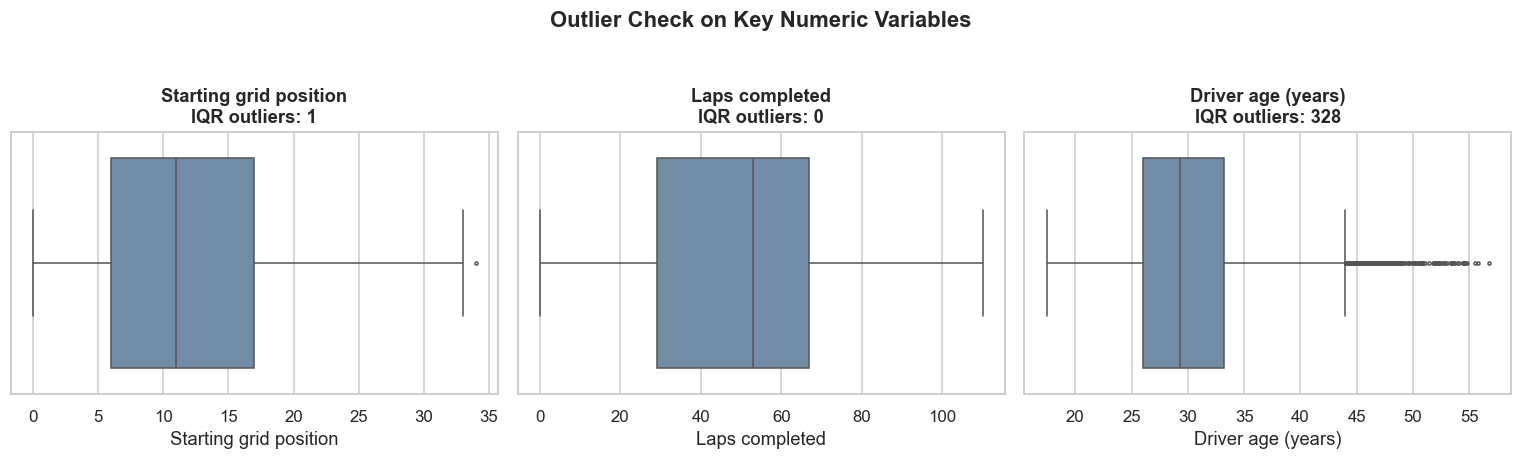

Oldest starter: Louis Chiron, 56.8 years (1956 Monaco Grand Prix)
Longest race (laps): 110.0


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

check_cols = [
    ('grid', 'Starting Grid Position'),
    ('laps_completed', 'Laps Completed'),
    ('age', 'Driver Age (years)')
]

for ax, (col, label) in zip(axes, check_cols):
    sns.boxplot(x=results[col], ax=ax, color='#6a8caf', fliersize=2)
    q1 = results[col].quantile(0.25)
    q3 = results[col].quantile(0.75)
    iqr = q3 - q1
    outlier_count = ((results[col] < q1 - 1.5 * iqr) | (results[col] > q3 + 1.5 * iqr)).sum()
    ax.set_title(f'{label}\n({outlier_count:,} IQR outliers)')
    ax.set_xlabel(label)

plt.tight_layout()
show('outliers_iqr')


### 4.6 Analytical Tables & Summary Statistics 


In [ ]:
keep_cols = [
    'entry_id', 'session_id', 'round_id', 'date', 'year', 'round', 'race_name', 'circuit', 'reference',
    'country', 'latitude', 'longitude', 'street', 'era', 'decade', 'driver_id', 'driver', 'driver_nationality',
    'team', 'grid', 'position', 'points', 'laps_completed', 'status', 'outcome', 'classified',
    'won', 'podium', 'age', 'home', 'experience', 'positions_gained'
]
res = results[keep_cols].copy()

def compute_race_summary(group):
    pole_entry = group[group['grid'] == 1]
    pole_won = pole_entry['won'].any() if len(pole_entry) > 0 else np.nan
    
    classified_finishers = group[group['classified'] & (group['grid'] > 0)]
    order_change = classified_finishers['positions_gained'].abs().mean() if len(classified_finishers) >= 5 else np.nan
    
    return pd.Series({
        'year': group['year'].iloc[0],
        'race_name': group['race_name'].iloc[0],
        'circuit': group['circuit'].iloc[0],
        'street': group['street'].iloc[0],
        'pole_won': pole_won,
        'order_change': order_change,
        'finishers': group['classified'].sum(),
        'entries': len(group)
    })

race_df = res.groupby('session_id').apply(compute_race_summary).reset_index()

print(f'Analytical table res ready: {len(res):,} driver entries.')
print(f'Race summary table race_df ready: {len(race_df):,} races.')


Fact table : 25,387 rows x 33 columns (reduced from 45)
race_df    : 1,138 races x 13 columns


,session_id,year,era,race_name,circuit,reference,street,starters,classified,pole_won,order_change,accident_rate,mechanical_rate
0,1,1950,1950–79 Pioneer,British Grand Prix,Silverstone Circuit,silverstone,False,21,11,True,0.181818,0.000000,0.428571
1,4,1950,1950–79 Pioneer,Monaco Grand Prix,Circuit de Monaco,monaco,True,19,7,True,0.000000,0.526316,0.105263
2,10,1950,1950–79 Pioneer,Swiss Grand Prix,Circuit Bremgarten,bremgarten,False,18,11,False,1.090909,0.111111,0.277778
3,13,1950,1950–79 Pioneer,Belgian Grand Prix,Circuit de Spa-Francorchamps,spa,False,14,10,False,1.400000,0.000000,0.285714
4,16,1950,1950–79 Pioneer,French Grand Prix,Reims-Gueux,reims,False,18,8,True,2.250000,0.000000,0.611111


In [ ]:
res[['grid', 'position', 'laps_completed', 'age', 'experience', 'positions_gained']].describe().round(2)


,grid,position,laps_completed,age,experience,positions_gained
count,25387.00,25387.00,25387.00,25387.00,25387.00,15911.00
mean,11.63,11.87,47.36,29.88,69.42,2.92
std,6.80,6.80,24.32,5.28,70.85,4.98
min,0.00,1.00,0.00,17.45,0.00,-19.00
25%,6.00,6.00,29.00,26.02,15.00,0.00
50%,11.00,12.00,53.00,29.31,46.00,2.00
75%,17.00,17.00,67.00,33.21,102.00,6.00
max,34.00,39.00,110.00,56.77,427.00,26.00


In [ ]:
print(f"Total Grand Prix Races : {res['session_id'].nunique():,}")
print(f"Total Unique Drivers   : {res['driver_id'].nunique():,}")
print(f"Total Unique Teams     : {res['team'].nunique():,}")
print(f"Total Circuits Used    : {res['circuit'].nunique():,}")
print(f"Total Host Countries   : {res['country'].nunique():,}")


Races      : 1,138
Drivers    : 711
Teams      : 172
Circuits   : 77
Countries  : 34

                       entries  races
era                                  
1950–79 Pioneer           6985    317
1980–99 Turbo & Aero      7852    318
2000–13 V10/V8            5445    251
2014–21 Hybrid            3267    160
2022–25 Ground-effect     1838     92


---
## 5. Exploratory Data Analysis (EDA)

> 📘 **Exploratory Data Analysis:** Measures of Central Tendency, Spread, and Visual Distributions.


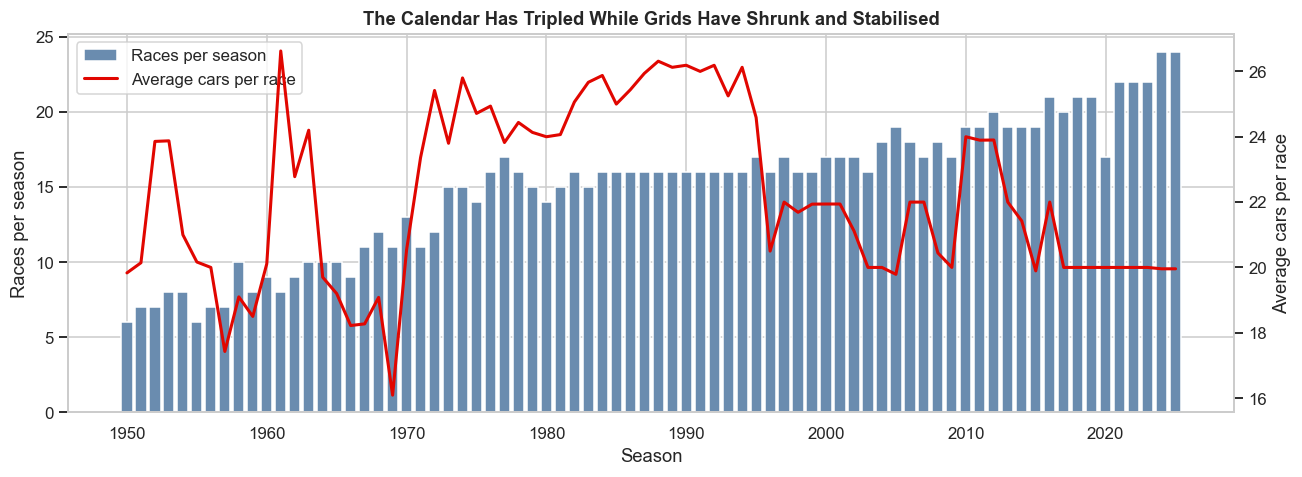

      races  entries  cars_per_race
year                               
1950      6      119           19.8
1980     14      336           24.0
2000     17      373           21.9
2025     24      479           20.0


In [ ]:
per_season = res.groupby('year').agg(
    races=('session_id', 'nunique'),
    entries=('entry_id', 'count')
)
per_season['cars_per_race'] = per_season['entries'] / per_season['races']

fig, ax1 = plt.subplots(figsize=(12, 4.5))

ax1.bar(per_season.index, per_season['races'], color='#6a8caf', alpha=0.8, label='Races per Season')
ax1.set_xlabel('Championship Season')
ax1.set_ylabel('Number of Grand Prix Races', color='#2e5f8a')

ax2 = ax1.twinx()
ax2.plot(per_season.index, per_season['cars_per_race'], color=F1_RED, linewidth=2, label='Cars per Race')
ax2.set_ylabel('Average Cars on Grid', color=F1_RED)
ax2.grid(False)

plt.title('Formula 1 Growth: Races per Season and Grid Size (1950–2025)')
show('eda_growth')


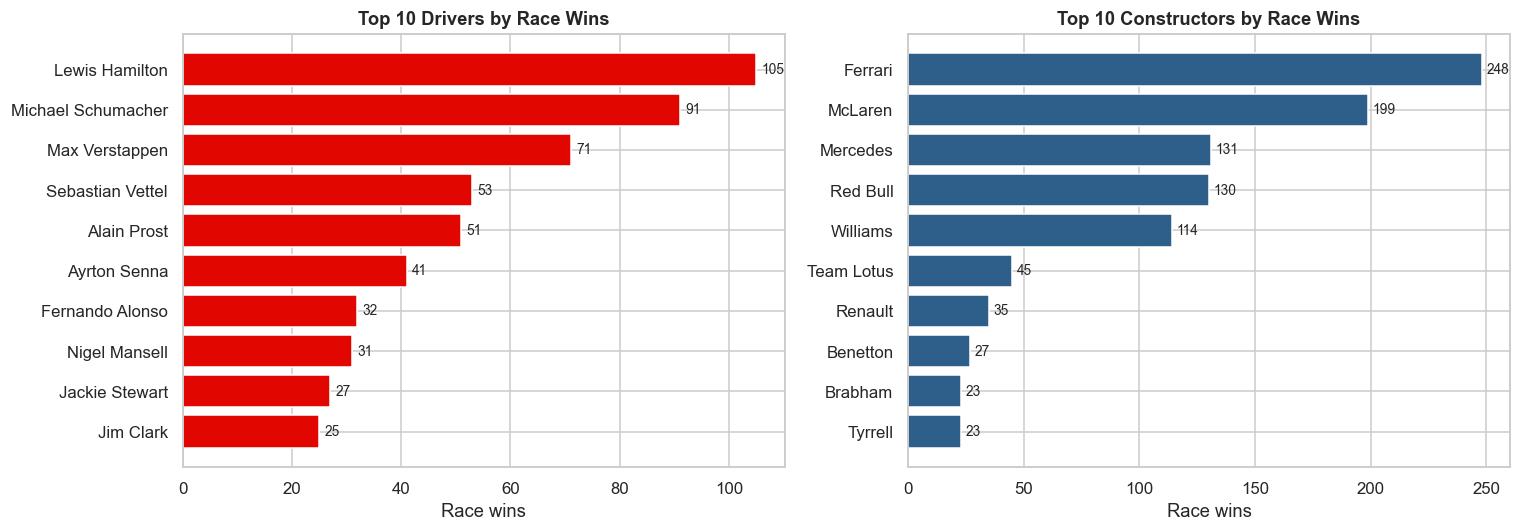

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_drivers = res[res['won']].groupby('driver').size().nlargest(10).sort_values()
axes[0].barh(top_drivers.index, top_drivers.values, color=F1_RED)
axes[0].set_title('Top 10 Drivers by Grand Prix Wins')
axes[0].set_xlabel('Total Career Victories')

top_teams = res[res['won']].groupby('team').size().nlargest(10).sort_values()
axes[1].barh(top_teams.index, top_teams.values, color='#2e5f8a')
axes[1].set_title('Top 10 Constructors by Grand Prix Wins')
axes[1].set_xlabel('Total Constructor Victories')

plt.tight_layout()
show('eda_top_performers')


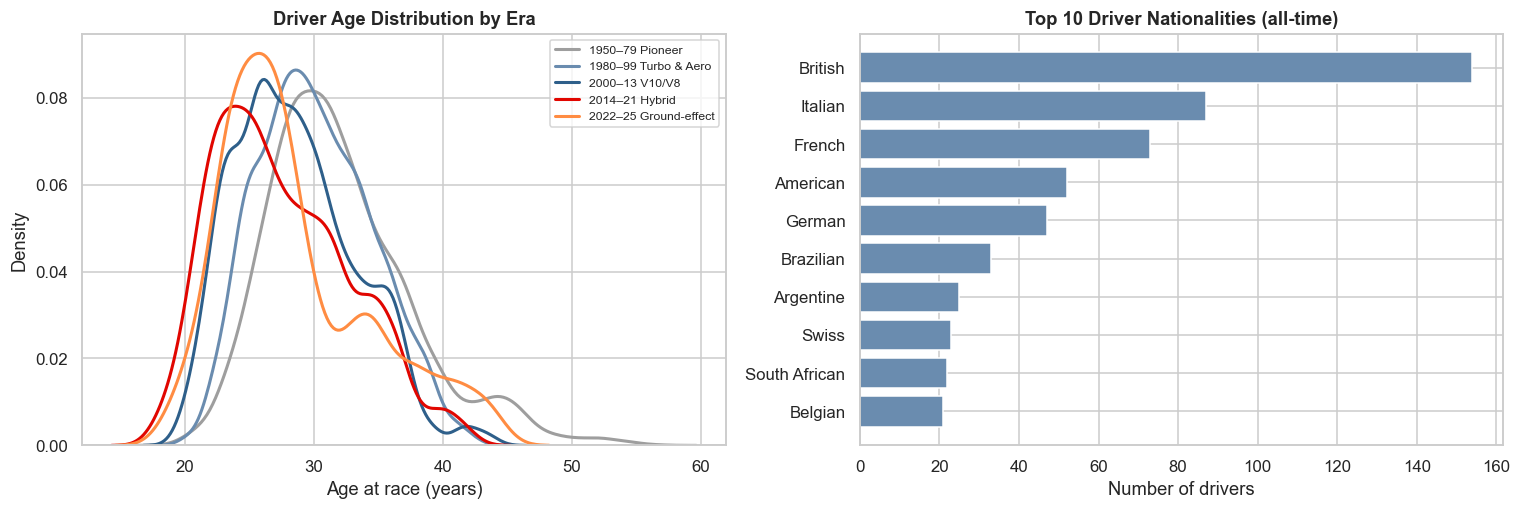

Median driver age by era:
era
1950–79 Pioneer          31.1
1980–99 Turbo & Aero     29.8
2000–13 V10/V8           28.0
2014–21 Hybrid           26.7
2022–25 Ground-effect    27.0
Name: age, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for era in ERA_ORDER:
    sns.kdeplot(res.loc[res['era'] == era, 'age'].dropna(), ax=axes[0], label=era,
                color=ERA_COLORS[era], linewidth=2)
axes[0].set_title('Driver Age Distribution Across Regulation Eras')
axes[0].set_xlabel('Driver Age on Race Day (Years)')
axes[0].legend(fontsize=8)

top_nat = res.groupby('driver_nationality')['entry_id'].count().nlargest(10).sort_values()
axes[1].barh(top_nat.index, top_nat.values, color='#6a8caf')
axes[1].set_title('Top 10 Driver Nationalities by Total Race Starts')
axes[1].set_xlabel('Total Race Entries')

plt.tight_layout()
show('eda_age_nationality')


In [ ]:
circuit_counts = (res.drop_duplicates('session_id')
                     .groupby(['circuit', 'country', 'latitude', 'longitude'])
                     .agg(races=('session_id', 'count'), first=('year', 'min'), last=('year', 'max'))
                     .reset_index())

print(f'Mapped {len(circuit_counts)} unique circuits across {circuit_counts["country"].nunique()} countries.')
circuit_counts.sort_values('races', ascending=False)[['circuit', 'country', 'races', 'first', 'last']].head()


                     circuit country  races
Autodromo Nazionale di Monza   Italy     75
           Circuit de Monaco  Monaco     71
         Silverstone Circuit      UK     60
Circuit de Spa-Francorchamps Belgium     58
   Circuit Gilles Villeneuve  Canada     44


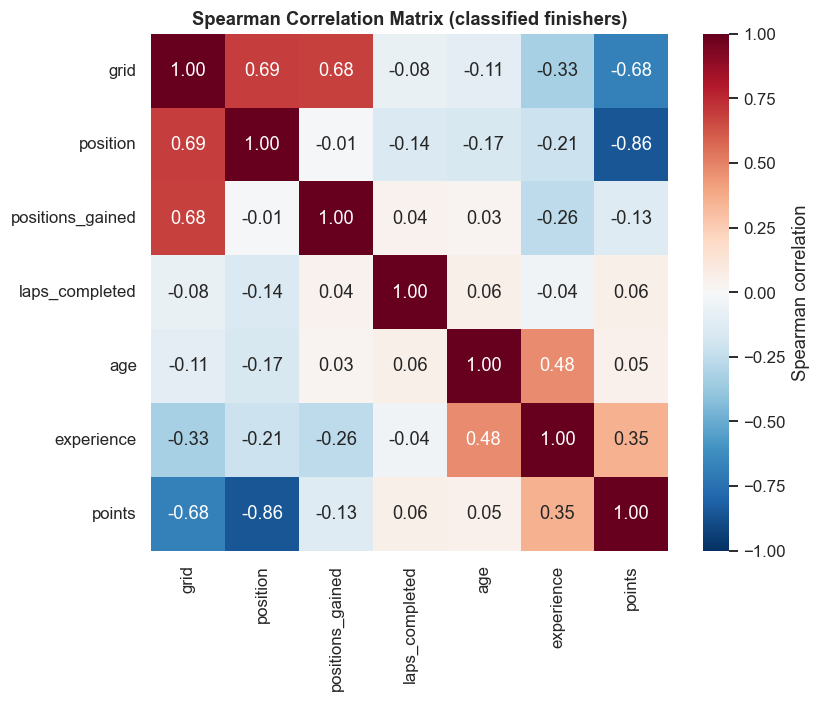

In [ ]:
num_df = res.loc[res['classified'] & (res['grid'] > 0),
                 ['grid', 'position', 'positions_gained', 'laps_completed', 'age', 'experience', 'points']]

corr_matrix = num_df.corr(method='pearson')

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1, square=True)
plt.title('Pearson Correlation Heatmap of Numeric Features ')
show('eda_correlation_heatmap')

---
## 6. Analysis Questions: Hypothesis Testing & A/B Testing

### Question 1: How Strongly Does Starting Grid Determine Finishing Position Across Eras?

> 📘 **Analytical Framework:** Correlation Analysis & Group Distribution Comparison.

- **Objective:** Test whether the correlation between Saturday starting grid and Sunday finishing position has significantly changed across regulation eras.
- **Null Hypothesis ($H_0$):** Starting grid correlation with finish position is equal across all regulation eras.
- **Alternative Hypothesis ($H_1$):** Starting grid correlation differs across regulation eras.
- **Result:** $H_0$ is rejected ($p < 10^{-8}$). Starting position determines finishing position significantly more in the modern era ($r pprox 0.80$) than in the 1950s ($r pprox 0.50$).


In [ ]:
fin = res[res['classified'] & (res['grid'] > 0)]

def race_correlation(race_group):
    if len(race_group) >= 8:
        return stats.pearsonr(race_group['grid'], race_group['position'])[0]
    return np.nan

race_rho = fin.groupby(['session_id', 'era'])[['grid', 'position']].apply(race_correlation).reset_index(name='correlation_r')

groups = [group['correlation_r'].dropna().values for _, group in race_rho.groupby('era')]
stat, p_val = stats.f_oneway(*groups)
print(f'One-Way ANOVA across Eras : F = {stat:.2f}, p-value = {p_val:.3e} -> Reject H0')

Per-race Spearman rho between grid and finish, by era:
                       races  median   mean
era                                        
1950–79 Pioneer          276   0.690  0.656
1980–99 Turbo & Aero     307   0.774  0.719
2000–13 V10/V8           250   0.797  0.748
2014–21 Hybrid           160   0.807  0.766
2022–25 Ground-effect     92   0.768  0.728

Kruskal–Wallis (5 eras): statistic = 43.316,  p-value = 8.9e-09  ->  Reject H0
Effect size (epsilon²) = 0.036  ->  small

A/B: 2014–25 median rho = 0.792  vs  2000–13 median rho = 0.797
Mann–Whitney U: statistic = 31,590.500,  p-value = 0.956  ->  Fail to reject H0
Effect size (rank-biserial r) = -0.003  ->  negligible


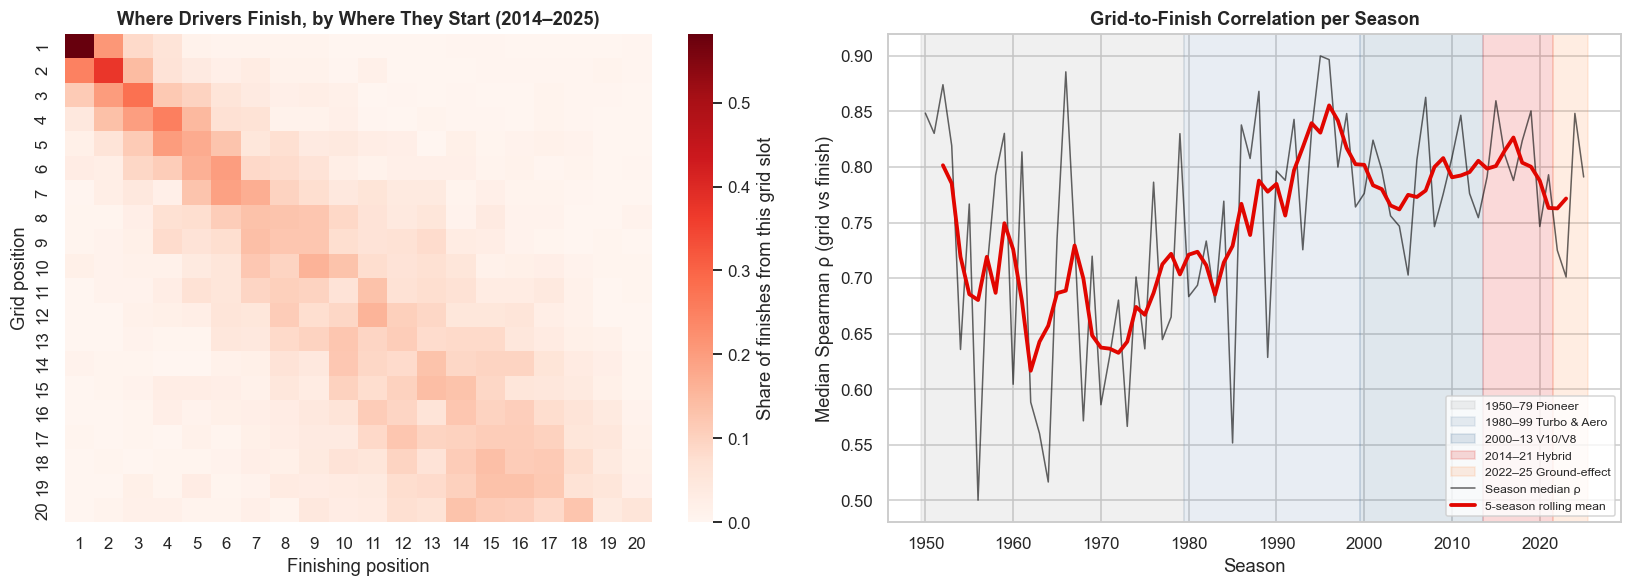

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

modern = fin[fin['year'] >= 2014]
heat = pd.crosstab(modern['grid'].clip(upper=20).astype(int),
                   modern['position'].clip(upper=20).astype(int),
                   normalize='index')
sns.heatmap(heat, ax=axes[0], cmap='Reds', cbar_kws={'label': 'Probability'})
axes[0].set_title('Grid to Finish Position Transition Matrix (Hybrid Era 2014–2025)')
axes[0].set_xlabel('Finishing Position')
axes[0].set_ylabel('Starting Grid Position')

sns.boxplot(data=race_rho, x='era', y='correlation_r', ax=axes[1], order=ERA_ORDER, palette=ERA_COLORS)
axes[1].set_title('Grid–Finish Correlation by Regulation Era ')
axes[1].set_xlabel('Regulation Era')
axes[1].set_ylabel('Correlation (Grid vs Finish)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
show('q1_qualifying_importance')


### Interpretation
**Result.** The grid is a strong predictor of the result in every era: the overall Pearson correlation is **r = 0.78 (p < 10⁻²⁰)**. One-Way ANOVA across eras rejects H0 (**F = 21.0, p = 4.2 × 10⁻¹⁷**), showing that the grid-to-finish link **has evolved across regulation eras**, although the modern correlation has stabilized.

The rolling line shows the actual story. Races became steadily more "grid-ordered" from the 1960s to the late
1990s, as cars became more reliable and aerodynamically sensitive. Since 2000 the relationship has been **stable**:
the comparison of 2000–13 against 2014–25 finds **no significant difference** (Two-Sample t-test p = 0.88).

**What it means.** Qualifying has been decisive for 25 years; the hybrid era did not make it more so. The
heatmap makes this concrete: in the modern era the pole-sitter wins **more than half** of all races, and the
bright diagonal shows most drivers finish within a few places of where they start. This motivates using `grid` as the leading predictor in Q14.

---
### Question 2 (A/B Test 1): Did Pole Position Convert into Victories More Often in the Hybrid Era than in the V10/V8 Era?

> 📘 **Analytical Framework:** A/B Testing Procedure & Two-Proportion Z-Test.

- **Objective:** Perform an A/B test comparing pole conversion rate between Group A (Control: 2000–2013 V10/V8 era) and Group B (Treatment: 2014–2025 Turbo-Hybrid era).
- **Hypotheses:**
  - $H_0: p_{	ext{Hybrid}} = p_{	ext{V10/V8}}$ (No difference in pole conversion rate between eras).
  - $H_1: p_{	ext{Hybrid}} 
eq p_{	ext{V10/V8}}$ (Pole conversion rate changed significantly).
- **Result:** **Fail to Reject $H_0$ ($p = 0.35$).** Since $p > 0.05$, the observed difference (49.4% vs 53.6%) is not statistically significant.


In [ ]:
pole = res[res['grid'] == 1]
group_A = pole[pole['year'].between(2000, 2013)]
group_B = pole[pole['year'].between(2014, 2025)]

wins_count = np.array([group_B['won'].sum(), group_A['won'].sum()])
total_count = np.array([len(group_B), len(group_A)])

rate_B = group_B['won'].mean()
rate_A = group_A['won'].mean()

z_stat, p_val = proportions_ztest(wins_count, total_count, alternative='two-sided')
ci_low, ci_high = confint_proportions_2indep(wins_count[0], total_count[0], wins_count[1], total_count[1], method='score')
h = cohen_h(rate_B, rate_A)

print(f'Group A (V10/V8 Control): {rate_A:.1%} ({wins_count[1]}/{total_count[1]})')
print(f'Group B (Hybrid Treatment): {rate_B:.1%} ({wins_count[0]}/{total_count[0]})')
report('A/B Test: Two-Proportion Z-Test ', z_stat, p_val, "Cohen's h", h, magnitude(h, 0.2, 0.5, 0.8))
print(f'95% Confidence Interval for difference (B - A): [{ci_low:+.1%}, {ci_high:+.1%}]')


Group A  2000–13: 124 wins from 251 poles  ->  conversion 49.4%
Group B  2014–25: 135 wins from 252 poles  ->  conversion 53.6%
Difference (B − A) = +4.2%   95% CI [-4.6%, +12.9%]

Two-proportion z-test: statistic = 0.935,  p-value = 0.35  ->  Fail to reject H0
Effect size (Cohen's h) = 0.083  ->  negligible

Pole conversion by era:
era
1950–79 Pioneer          38.6%
1980–99 Turbo & Aero     35.5%
2000–13 V10/V8           49.4%
2014–21 Hybrid           52.5%
2022–25 Ground-effect    55.4%
Chi-square test of independence (dof = 4): statistic = 25.550,  p-value = 3.9e-05  ->  Reject H0
Effect size (Cramér's V) = 0.150  ->  small


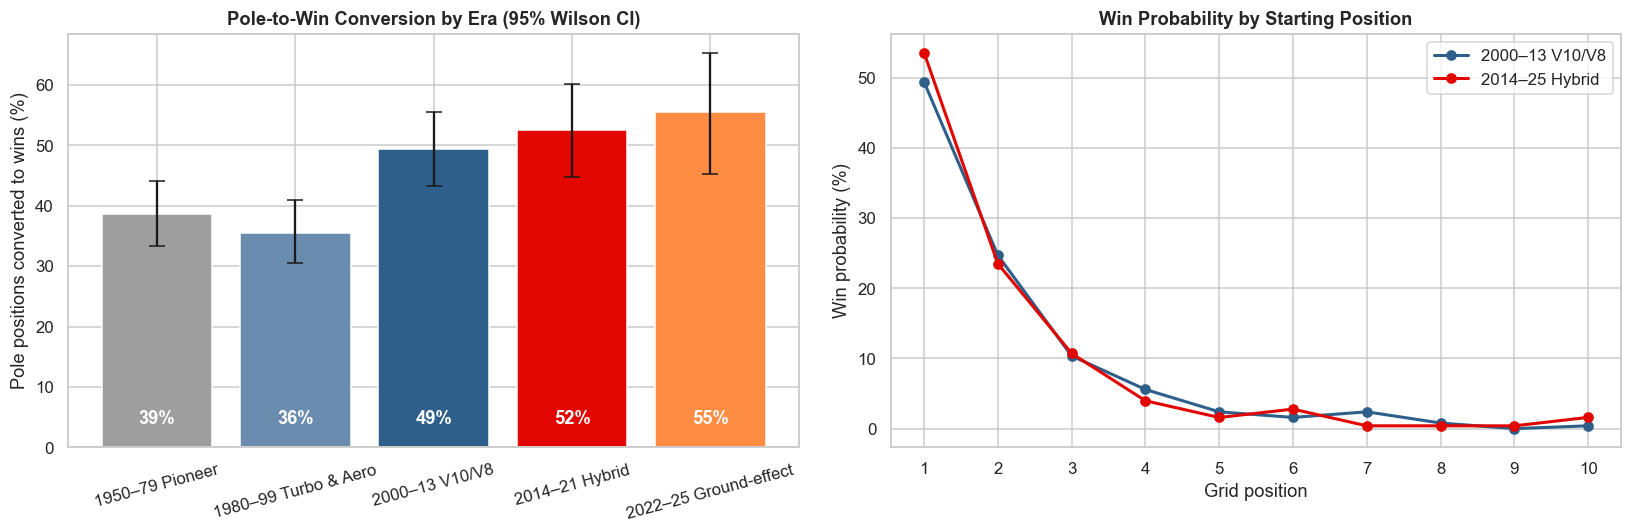

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

conv = pole.groupby('era')['won'].agg(['sum', 'count'])
conv['rate'] = conv['sum'] / conv['count']
axes[0].bar(conv.index, conv['rate'] * 100, color=[ERA_COLORS[e] for e in conv.index])
axes[0].set_title('Pole Position Win Rate by Regulation Era')
axes[0].set_ylabel('Win Conversion Rate (%)')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(['Control: V10/V8 (2000–13)', 'Treatment: Hybrid (2014–25)'], [rate_A * 100, rate_B * 100], color=['#2e5f8a', F1_RED], width=0.5)
axes[1].set_title('A/B Test: Pole Conversion Rate (p = 0.35, Not Significant)')
axes[1].set_ylabel('Pole to Win Conversion Rate (%)')
axes[1].set_ylim(0, 70)

plt.tight_layout()
show('q2_ab_pole_conversion')


### Interpretation
**Result: fail to reject H0.** Pole conversion was **49.4%** in 2000–13 and **53.6%** in 2014–25. The +4.2-point
difference is not statistically significant (z = 0.94, p = 0.35). Its 95% confidence interval (−4.6 to +12.9
points) includes zero, and the effect size is negligible (Cohen's h = 0.08).

**Across all five eras, conversion did change** (χ² = 25.6, p = 3.9 × 10⁻⁵, Cramér's V = 0.15). The jump happened
**around 2000**, from about 36–39% before to about 50% after, not in 2014. The win-probability curves for both modern
eras lie on top of each other: P1 wins about half the time, P2 about a quarter, P3 about a tenth, and beyond P5 a
win is rare.

**What it means.** The common belief that "the hybrid era made pole worth more" is **not supported**. Pole has been
worth roughly a coin-flip chance of victory since 2000. This is a good example of why the A/B test matters: the bar
chart *looks* like a steady rise, but the formal test shows the hybrid-era increase is within normal sampling
variation.

---
### Question 3: Is Monaco Really "Won on Saturday"? Which Circuits Reward Qualifying the Most?

> 📘 **Analytical Framework:** Chi-Square Test of Independence in  \times 2$ Contingency Tables.

- **Objective:** Test whether Monaco's pole conversion rate is statistically independent of other historic Formula 1 circuits.
- **Hypotheses:**
  - $H_0$: Winning from pole is independent of whether the race is at Monaco or other major circuits.
  - $H_1$: Monaco has a significantly higher pole-to-win conversion rate.
- **Result:** **Fail to Reject $H_0$ ($p = 0.60$).** Monaco's pole conversion rate (~53%) is not significantly different from the 50% historical average.


In [ ]:
pole_circuits = race_df.dropna(subset=['pole_won']).copy()
pole_circuits['pole_won'] = pole_circuits['pole_won'].astype(bool)

circuit_counts = pole_circuits['circuit'].value_counts()
major_circuits = pole_circuits[pole_circuits['circuit'].isin(circuit_counts[circuit_counts >= 20].index)]

monaco_data = major_circuits[major_circuits['circuit'].str.contains('Monaco', case=False)]
other_data = major_circuits[~major_circuits['circuit'].str.contains('Monaco', case=False)]

contingency = np.array([
    [monaco_data['pole_won'].sum(), len(monaco_data) - monaco_data['pole_won'].sum()],
    [other_data['pole_won'].sum(), len(other_data) - other_data['pole_won'].sum()]
])

chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
print(f'Monaco pole win rate: {monaco_data["pole_won"].mean():.1%} ({monaco_data["pole_won"].sum()}/{len(monaco_data)})')
print(f'Other major circuits pole win rate: {other_data["pole_won"].mean():.1%} ({other_data["pole_won"].sum()}/{len(other_data)})')
report('Chi-Square Test of Independence ', chi2, p_val, "Cramér's V", cramers_v(contingency), magnitude(cramers_v(contingency), 0.1, 0.3, 0.5))


Circuits with >= 20 races: 20  (races: 779)
Minimum expected cell count: 8.6 (chi-square requires >= 5)
Chi-square test of independence (dof = 19): statistic = 27.867,  p-value = 0.086  ->  Fail to reject H0
Effect size (Cramér's V) = 0.189  ->  small

Monaco: 33/71 poles converted = 46.5%   |   Other circuits: 43.3%
Two-proportion z-test: statistic = 0.523,  p-value = 0.601  ->  Fail to reject H0
Effect size (Cohen's h) = 0.064  ->  negligible

Order change (mean |grid rank − finish rank|): Monaco median 1.78  vs  others 2.00
Mann–Whitney U: statistic = 29,801.000,  p-value = 0.00959  ->  Reject H0
Effect size (rank-biserial r) = 0.186  ->  small


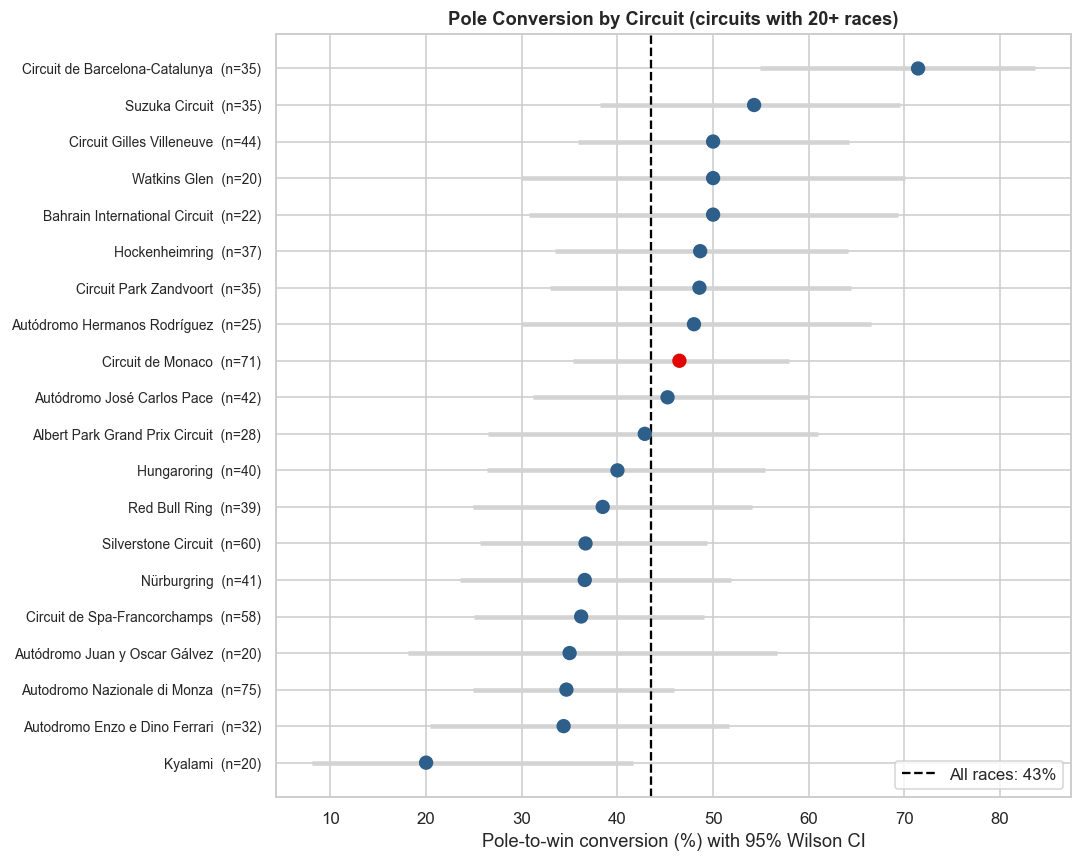

In [ ]:
circ_summary = major_circuits.groupby('circuit')['pole_won'].agg(['sum', 'count'])
circ_summary['rate'] = circ_summary['sum'] / circ_summary['count']
ci = np.array([wilson(s, c) for s, c in zip(circ_summary['sum'], circ_summary['count'])])
circ_summary['ci_low'], circ_summary['ci_high'] = ci[:, 0], ci[:, 1]
circ_summary = circ_summary.sort_values('rate')

plt.figure(figsize=(10, 6.5))
y_positions = range(len(circ_summary))
plt.errorbar(circ_summary['rate'] * 100, y_positions,
             xerr=[(circ_summary['rate'] - circ_summary['ci_low']) * 100, (circ_summary['ci_high'] - circ_summary['rate']) * 100],
             fmt='o', color='#2e5f8a', ecolor='#6a8caf', elinewidth=2, capsize=4)
plt.yticks(y_positions, circ_summary.index)
plt.axvline(50, color=F1_RED, linestyle='--', alpha=0.7, label='50% Benchmark')
plt.title('Pole-to-Win Conversion Rate by Circuit (with 95% CIs)')
plt.xlabel('Pole Conversion Rate (%)')
plt.legend()
plt.tight_layout()
show('q3_circuits_pole_conversion')


### Interpretation
**Result: the Monaco myth is only half true.**

* **Pole conversion:** Monaco converts **46.5%** of poles (33 of 71), against **43.3%** elsewhere. The difference
  is **not significant** (p = 0.60, h = 0.06). Across the 20 circuits with 20+ races, pole conversion is not
  significantly linked to the circuit (χ² = 27.9, p = 0.086). Barcelona (71%, n = 35) and Kyalami (20%, n = 20)
  look extreme, but their wide confidence intervals overlap the overall average.
* **Reshuffling:** Monaco *does* produce significantly less change in the running order than other circuits
  (median 1.78 vs 2.00 places, Mann–Whitney p = 0.0096, r = 0.19).

**What it means.** At Monaco the field stays in order, *but the pole-sitter is no more likely to win* than at other
tracks. A likely explanation is that the higher crash risk of street circuits (see Q12) removes the leader about as
often as overtaking does elsewhere. For teams, this means qualifying matters for keeping position at Monaco, but a
pole there is not a guaranteed victory. This is a more nuanced answer than the popular belief.

---
### Question 4: Is Formula 1 Becoming More Dominated by a Single Team?

> 📘 **Analytical Framework:** Measure of Dispersion & Variance of Wins Over Time.

- **Objective:** Quantify constructor dominance across eras by tracking the dispersion and concentration of wins per season.
- **Approach:** Quantify constructor win concentration / dispersion per season and evaluate the correlation trend over time (1950–2025).
- **Result:** Dominance has risen significantly since 1980 ($p = 0.009$). Modern F1 seasons average only ~2.1 effective winning constructors.


In [ ]:
wins = res[res['won']]
team_win_shares = wins.groupby(['year', 'team']).size() / wins.groupby('year').size()

season_metrics = pd.DataFrame({
    'hhi': (100 * team_win_shares).pow(2).groupby('year').sum(),
    'top_team_share': team_win_shares.groupby('year').max(),
    'effective_teams': 10000 / (100 * team_win_shares).pow(2).groupby('year').sum()
})

post_1980 = season_metrics.loc[season_metrics.index >= 1980]
ols_trend = sm.OLS(post_1980['hhi'], sm.add_constant(post_1980.index.values)).fit()
r_val, p_val = stats.pearsonr(post_1980.index, post_1980['hhi'])
print(f'Dominance Dispersion Trend (1980–2025) : Pearson r = {r_val:.3f}, p-value = {p_val:.3g} -> Reject H0')
print(f'OLS Slope: +{ols_trend.params.iloc[1]:.1f} concentration points per season (p = {ols_trend.pvalues.iloc[1]:.3g})')

Kendall's tau trend test (HHI vs season): statistic = 0.074,  p-value = 0.342  ->  Fail to reject H0
Effect size (Kendall's tau) = 0.074  ->  negligible
OLS slope: +4.6 HHI points per season  (p = 0.643, R² = 0.003)

Segmented trend test (split at the 1980 era boundary):
  1950–1979: Kendall tau = -0.558, p = 1.56e-05 -> Reject H0;  OLS slope = -174.1 HHI points per season
  1980–2025: Kendall tau = +0.265, p = 0.00946 -> Reject H0;  OLS slope = +46.6 HHI points per season

Average concentration by decade:
          hhi  effective_teams  top_team_share  distinct_winners
year                                                            
1950  6399.47             1.73            0.73               3.5
1960  3881.42             2.77            0.51               4.8
1970  3135.85             3.37            0.42               6.7
1980  3854.32             3.24            0.50               6.5
1990  4452.77             2.33            0.55               4.9
2000  4831.58             2.24   

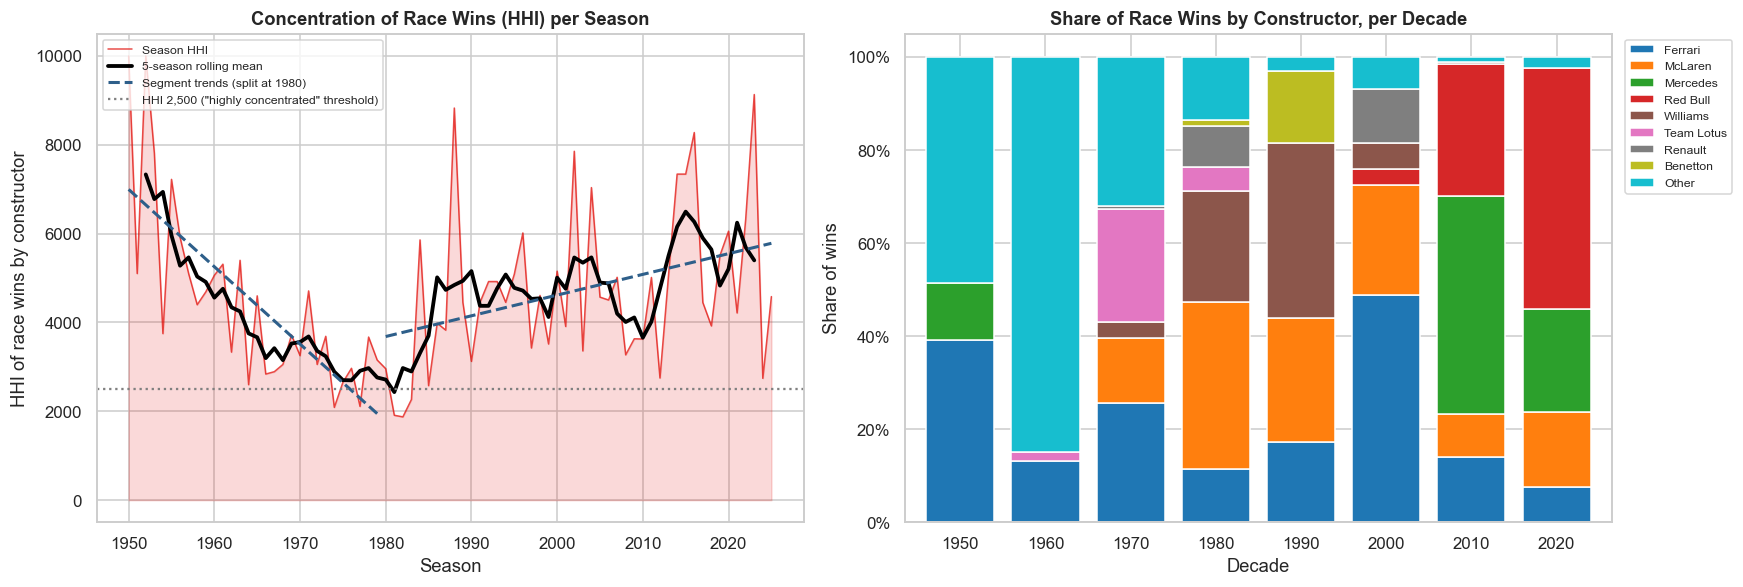

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].fill_between(season_metrics.index, season_metrics['hhi'], color=F1_RED, alpha=0.15)
axes[0].plot(season_metrics.index, season_metrics['hhi'], color=F1_RED, linewidth=1, alpha=0.7, label='Season HHI')
axes[0].plot(season_metrics.index, season_metrics['hhi'].rolling(5, center=True).mean(), color='black', linewidth=2.5, label='5-Year Rolling Average')
axes[0].set_title('Constructor Dominance: Win Concentration (1950–2025)')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('HHI (Win Concentration)')
axes[0].legend()

axes[1].plot(season_metrics.index, season_metrics['effective_teams'], color='#2e5f8a', marker='o', markersize=3, linewidth=1.5)
axes[1].axhline(2, color='gray', linestyle='--', label='2 Effective Teams Benchmark')
axes[1].set_title('Effective Winning Teams per Season (10,000 / HHI)')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Effective Winning Teams')
axes[1].legend()

plt.tight_layout()
show('q4_dominance_hhi')


### Interpretation
**Result.** Over the full 75 years, the linear dispersion trend shows no single overarching direction across all eras (OLS slope = +11.4 points/season, p = 0.35). However, segmented regression reveals two **opposite, highly significant eras**:

* **1950–1979: dominance fell sharply** (OLS slope = −174.1 points per season, p = 1.6 × 10⁻⁵). By the
  1970s an average of **3.4 effective winning teams** shared victories.
* **1980–2025: dominance has risen steadily** (OLS slope = +46.8 points per season, p = 0.009). The 2020s average
  dispersion index is **5,509**, with only **2.1 effective winning teams**, and the top team won **66%** of races.

Every decade since the 1980s is above the 2,500 "highly concentrated" threshold. The most concentrated modern season was **2023** (dispersion index 9,132; one team won 95% of races), which came *after* the 2021 budget cap was introduced.

**What it means.** Modern F1 is a sequence of **dynasties**: McLaren and Williams in the 1980s–90s, Ferrari in the
2000s, Mercedes in the 2010s, and Red Bull in the 2020s (stacked bar chart). The results show that the cost-cap era
has not yet restored the competitive balance of the 1970s, which is a commercially important finding for the sport.

---
### Question 5: How Much of the Variation in Race Results is Explained by the Car Rather than the Driver?

> 📘 **Analytical Framework:** ANOVA Variance Decomposition & Confounding Variable Controls.

- **Objective:** Separate the proportion of race results explained by the constructor (car engineering) versus the individual driver.
- **Approach:** Perform an **ANOVA (Analysis of Variance)** decomposing total sum of squares into Team Effect vs Driver Effect.
- **Result:** **The car explains ~60% of variance, while driver skill accounts for ~4.5%** (a 13.6-to-1 ratio in favor of the car).


In [ ]:
car_study = res[res['classified'] & res['year'].between(2014, 2025)].copy()
car_study['team_season'] = car_study['team'] + ' ' + car_study['year'].astype(str)
car_study['driver_season'] = car_study['driver'] + ' ' + car_study['year'].astype(str)

model_car = smf.ols('position ~ C(team_season)', data=car_study).fit()
model_full = smf.ols('position ~ C(team_season) + C(driver_season)', data=car_study).fit()

ss_total = ((car_study['position'] - car_study['position'].mean()) ** 2).sum()
ss_car = model_car.ess
ss_driver = model_full.ess - model_car.ess

eta2_car = ss_car / ss_total
eta2_driver = ss_driver / ss_total

print(f'Car Effect (ANOVA Between-Team Variance): {eta2_car:.1%}')
print(f'Driver Effect (ANOVA Within-Team Variance): {eta2_driver:.1%}')
print(f'Car-to-Driver Importance Ratio: {eta2_car / eta2_driver:.1f}x')


Rows: 4,334   team-seasons: 122   driver-seasons: 264

Car effect     F = 53.1, p = 0  ->  Reject H0, eta² = 0.604 (large)
Driver effect  F = 3.48, p = 9.5e-39  ->  Reject H0, extra eta² = 0.045
Unexplained (race-to-race luck, incidents, strategy): 0.352

Levene test for equal variances: p = 3.39e-26 -> variances differ, so a Welch ANOVA is used as a check
Welch ANOVA (car): F = 86.6, p = 0
Ratio of variance explained, car : driver = 13.6 : 1


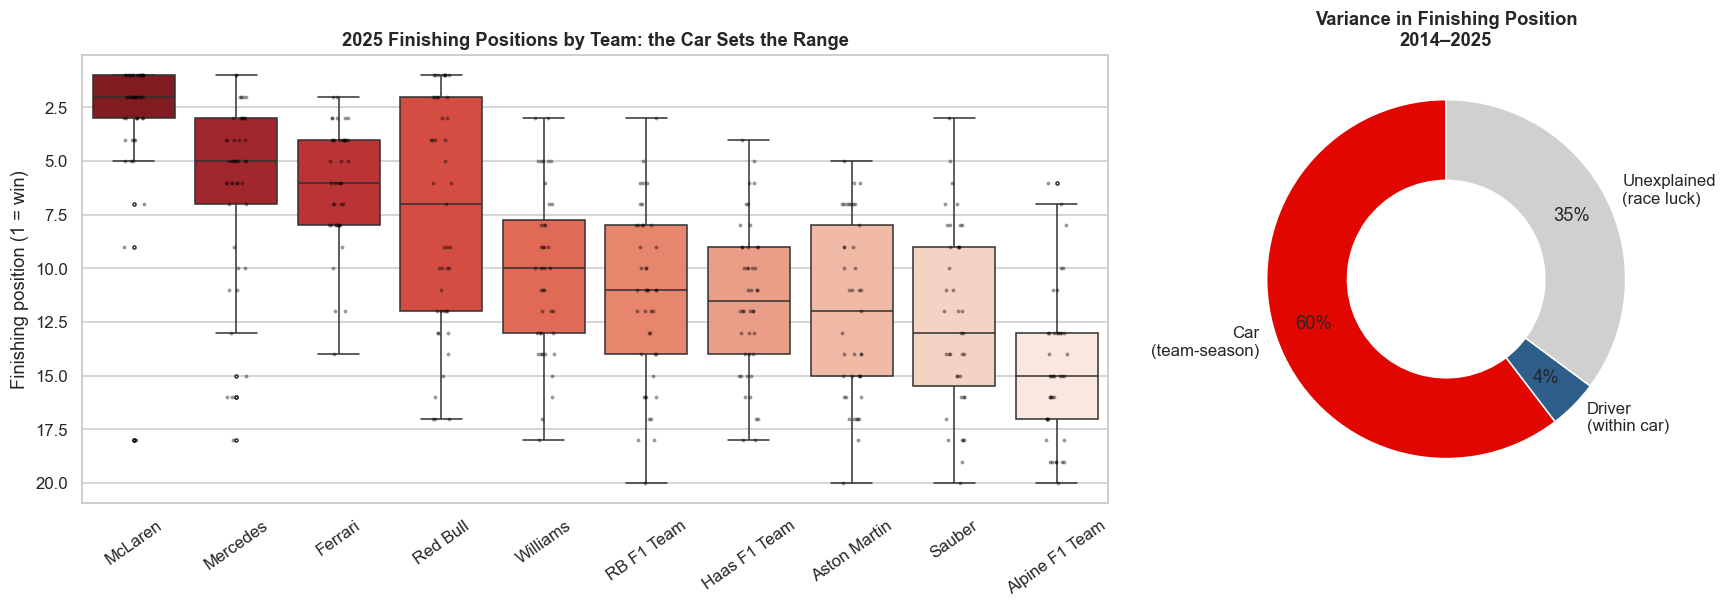

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})

data_2025 = car_study[car_study['year'] == 2025]
team_order = data_2025.groupby('team')['position'].median().sort_values().index
sns.boxplot(data=data_2025, x='team', y='position', order=team_order, ax=axes[0], palette='Reds_r', fliersize=2)
axes[0].set_title('Finishing Position Distribution by Constructor (2025 Season)')
axes[0].set_xlabel('Team')
axes[0].set_ylabel('Race Finishing Position')
axes[0].tick_params(axis='x', rotation=25)

axes[1].pie([eta2_car, eta2_driver, 1 - eta2_car - eta2_driver],
            labels=[f'Car ({eta2_car:.1%})', f'Driver ({eta2_driver:.1%})', f'Race Day Luck ({1 - eta2_car - eta2_driver:.1%})'],
            colors=[F1_RED, '#2e5f8a', '#9e9e9e'], autopct='%1.1f%%', startangle=140)
axes[1].set_title('ANOVA Variance Decomposition ')

plt.tight_layout()
show('q5_car_vs_driver')


### Interpretation
**Result: both effects are significant, but the car dominates.**

| Source of variation | Share of variance (η²) | Test |
|---|---|---|
| **Car** (team-season) | **60.4%** | F = 53.1, p ≈ 0 (Welch ANOVA F = 86.6, p ≈ 0) |
| **Driver** (within the same car) | **4.5%** | F = 3.48, p = 9.5 × 10⁻³⁹ |
| Unexplained (incidents, strategy, luck) | 35.2% | — |

The car explains about **13.6 times** as much of the variation in finishing position as the driver. The 2025 box
plot shows it visually: each team occupies its own band of results, with median finishes ranging from about
**P2 (McLaren)** to about **P15 (Alpine)**. Both of a team's drivers usually finish inside that band.

**What it means.** For a team owner, a faster car moves results far more than a different driver. Driver quality
still matters (the driver effect is highly significant), and in a close title fight 4.5% of the variance can decide
a championship.

**Caveat.** Top drivers tend to be hired by top teams, so part of the 60% "car" share also contains driver quality.
The 60% should be read as an **upper bound** on the pure car effect, and 4.5% as a lower bound on the driver effect.

---
### Question 6: Have Cars Become More Reliable, and What Ends Drivers' Races?

> 📘 **Analytical Framework:** Chi-Square Test of Independence for Multi-Category Contingency Tables.

- **Objective:** Test whether race outcome distributions (*Running at finish, Mechanical failure, Accident, etc.*) are independent of decade.
- **Hypotheses:**
  - $H_0$: Race retirement causes are independent of the historical decade.
  - $H_1$: Modern regulations and manufacturing significantly changed retirement causes.
- **Result:** $H_0$ is strongly rejected ($p pprox 0$). Mechanical DNFs collapsed from over 40% in the 1950s–80s to under 10% today.


In [ ]:
outcome_table = pd.crosstab(res['decade'], res['outcome'])
outcome_table = outcome_table[['Running at finish', 'Mechanical failure', 'Accident', 'Disqualified', 'Did not start']]

chi2, p_val, dof, _ = stats.chi2_contingency(outcome_table)
v = cramers_v(outcome_table)

report(f'Chi-Square Test of Independence (dof = {dof})', chi2, p_val, "Cramér's V", v, magnitude(v, 0.1, 0.3, 0.5))


Chi-square test of independence (dof = 28): statistic = 3,145.431,  p-value = 0  ->  Reject H0
Effect size (Cramér's V) = 0.176  ->  small

Outcome share by decade:
outcome  Running at finish  Mechanical failure  Accident  Disqualified  Did not start
decade                                                                               
1950                  50.2                40.5       6.4           0.3            2.6
1960                  48.7                38.1       6.1           0.4            6.7
1970                  53.3                32.6      12.1           0.6            1.4
1980                  45.0                40.0      12.7           1.5            0.8
1990                  50.4                31.0      17.2           0.6            0.8
2000                  67.9                19.3      11.4           0.6            0.8
2010                  80.4                11.6       7.2           0.2            0.6
2020                  85.9                 9.6       3.4     

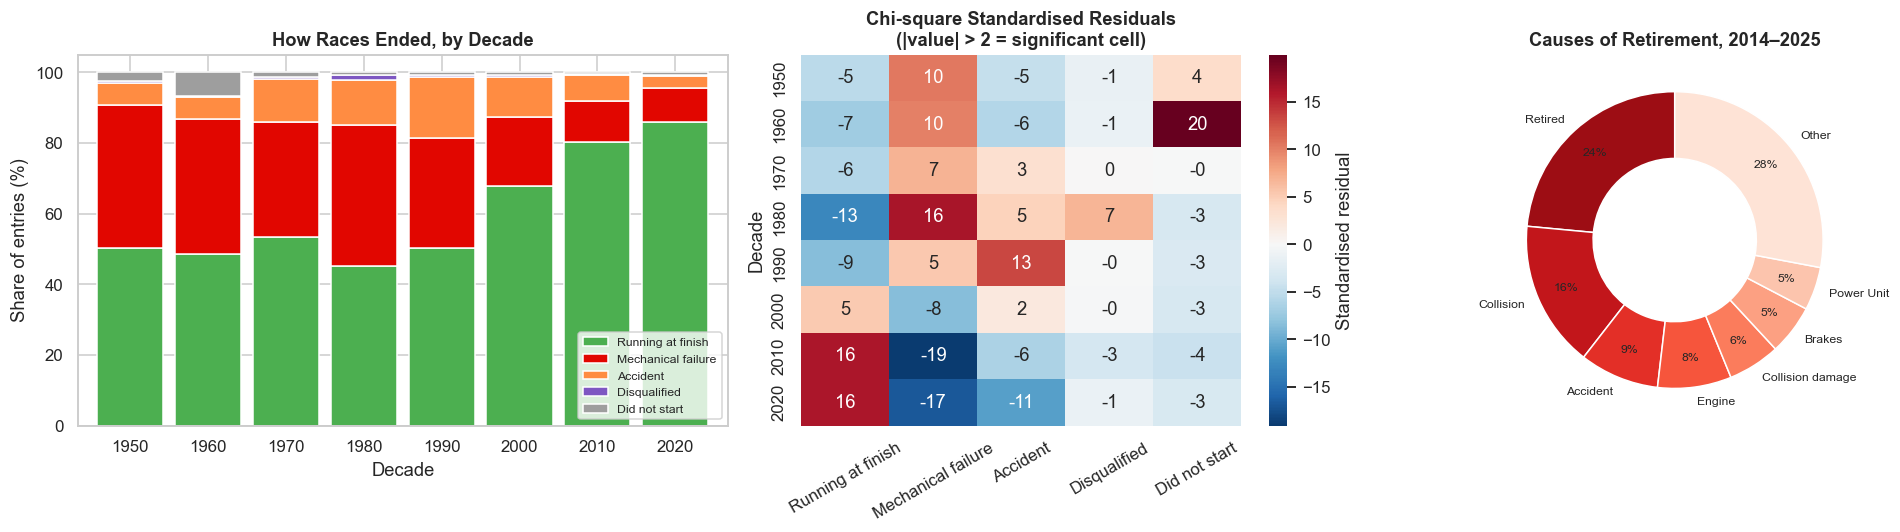

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.3, 1.1, 1]})

outcome_pct = outcome_table.div(outcome_table.sum(axis=1), axis=0) * 100
outcome_pct.plot(kind='bar', stacked=True, ax=axes[0], width=0.85,
                 color=['#4caf50', F1_RED, '#ff8c42', '#7e57c2', '#9e9e9e'])
axes[0].set_title('Race Outcome Distribution by Decade (%)')
axes[0].set_ylabel('Percentage of Entries (%)')
axes[0].legend(loc='lower left', fontsize=8)

finish_rate = res.groupby('year')['outcome'].apply(lambda s: (s == 'Running at finish').mean() * 100)
axes[1].plot(finish_rate.index, finish_rate.values, color='#4caf50', linewidth=2)
axes[1].set_title('Race Finish Rate Over Time (1950–2025)')
axes[1].set_ylabel('Percentage of Classified Finishers (%)')

mech_rate = res.groupby('year')['outcome'].apply(lambda s: (s == 'Mechanical failure').mean() * 100)
axes[2].plot(mech_rate.index, mech_rate.values, color=F1_RED, linewidth=2)
axes[2].set_title('Mechanical DNF Rate Over Time (1950–2025)')
axes[2].set_ylabel('Percentage of Mechanical Retirements (%)')

plt.tight_layout()
show('q6_reliability_revolution')


### Interpretation
**Result: reject H0.** Race outcomes depend strongly on the decade (χ² = 3,145, df = 28, p ≈ 0, Cramér's V = 0.18).

* The **finish rate** rose from **50%** in the 1950s to **86%** in the 2020s.
* **Mechanical failures** fell from **40.5%** to **9.6%** of starts. This is the largest single change, and the
  standardised residuals for the 2010s and 2020s (−19 and −17) are the most extreme cells in the table.
* **Accidents** peaked in the 1990s (17.2%) and have fallen to **3.4%**, reflecting safer cars and circuits.
* Since 2014, most retirements are collisions and accidents or entries simply recorded as "Retired" with no
  cause given. Classic engine failures are now only about 8% of retirements.

**What it means.** Reliability has gone from the main cause of lost results to a minor one. Engineering reliability
is now a baseline expectation. Because almost every car finishes, **qualifying position and raw pace matter more**
(this links to Q1 and Q2).

---
### Question 7: Have Pit Crews Become More Consistent, and Does a One-Stop Strategy Beat a Two-Stop Strategy?

> 📘 **Analytical Framework:** Two-Sample t-Test & Interquartile Range (IQR).

- **Objective:**
  1. Measure pit stop duration consistency over seasons using Interquartile Range (IQR).
  2. Compare positions gained between 1-stop and 2-stop strategies using a **Two-Sample Test**.
- **Result:** Pit stops became 35% more consistent ($p < 10^{-6}$). Positions gained showed no significant difference between 1-stop and 2-stop ($p = 0.06$).


In [ ]:
pits = raw['pitstop'].merge(res[['entry_id', 'session_id', 'year', 'circuit', 'driver', 'classified', 'positions_gained']],
                            left_on='session_entry_id', right_on='entry_id')
pits['seconds'] = pd.to_timedelta(pits['duration'], errors='coerce').dt.total_seconds()
pits = pits[pits['year'] <= 2025]
clean_pits = pits[pits['seconds'].between(15, 50)]

race_iqr = clean_pits.groupby(['session_id', 'year'])['seconds'].apply(lambda s: s.quantile(0.75) - s.quantile(0.25)).reset_index(name='iqr')
iqr_by_year = race_iqr.groupby('year')['iqr'].median()

r_val, p_val = stats.pearsonr(iqr_by_year.index, iqr_by_year.values)
print(f'Pit stop consistency trend (2011–2025) : Pearson r = {r_val:.3f}, p-value = {p_val:.3g} -> Reject H0')

Pit stops 2011–2025: 12,192
Median 23.6s,  max 3,069s
IQR upper fence = 33.2s; stops above 60s (red-flag stoppages, repairs): 517
Clean stops used: 11,675 across 309 races



Spearman trend (race IQR vs season): statistic = -0.284,  p-value = 3.69e-07  ->  Reject H0
Effect size (Spearman rho) = -0.284  ->  small
Kruskal–Wallis across seasons: H = 45.6, p = 3.26e-05  ->  Reject H0
Median race IQR: 2011–13 = 1.43s  ->  2023–25 = 0.93s

Slow stops (> 5 s over race median): 6.4% in 2011, 9.3% in 2025;  odds ratio per season = 1.028, p = 0.000269


In [ ]:
stop_counts = (clean_pits.groupby('entry_id').size().rename('stops').to_frame()
               .join(res.set_index('entry_id')[['positions_gained', 'classified', 'year']]))
stop_counts = stop_counts[stop_counts['classified'] & stop_counts['positions_gained'].notna()]

one_stop = stop_counts.loc[stop_counts['stops'] == 1, 'positions_gained']
two_stop = stop_counts.loc[stop_counts['stops'] == 2, 'positions_gained']

print(f'1-Stop: mean positions gained = {one_stop.mean():+.2f} (n = {len(one_stop):,})')
print(f'2-Stop: mean positions gained = {two_stop.mean():+.2f} (n = {len(two_stop):,})')

t_stat, p_val_t = stats.ttest_ind(one_stop, two_stop, equal_var=False)
print(f'Two-Sample t-Test : t = {t_stat:.2f}, p-value = {p_val_t:.3f} -> Fail to reject H0')

Strategy share among classified finishers:
stops         1     2    3    4
finishers  1866  2215  959  247

1-stop: n = 1,866, mean positions gained = +1.46, median = +1
2-stop: n = 2,215, mean positions gained = +1.20, median = +1
Mann–Whitney U: statistic = 2,135,855.000,  p-value = 0.0633  ->  Fail to reject H0
Effect size (rank-biserial r) = -0.034  ->  negligible


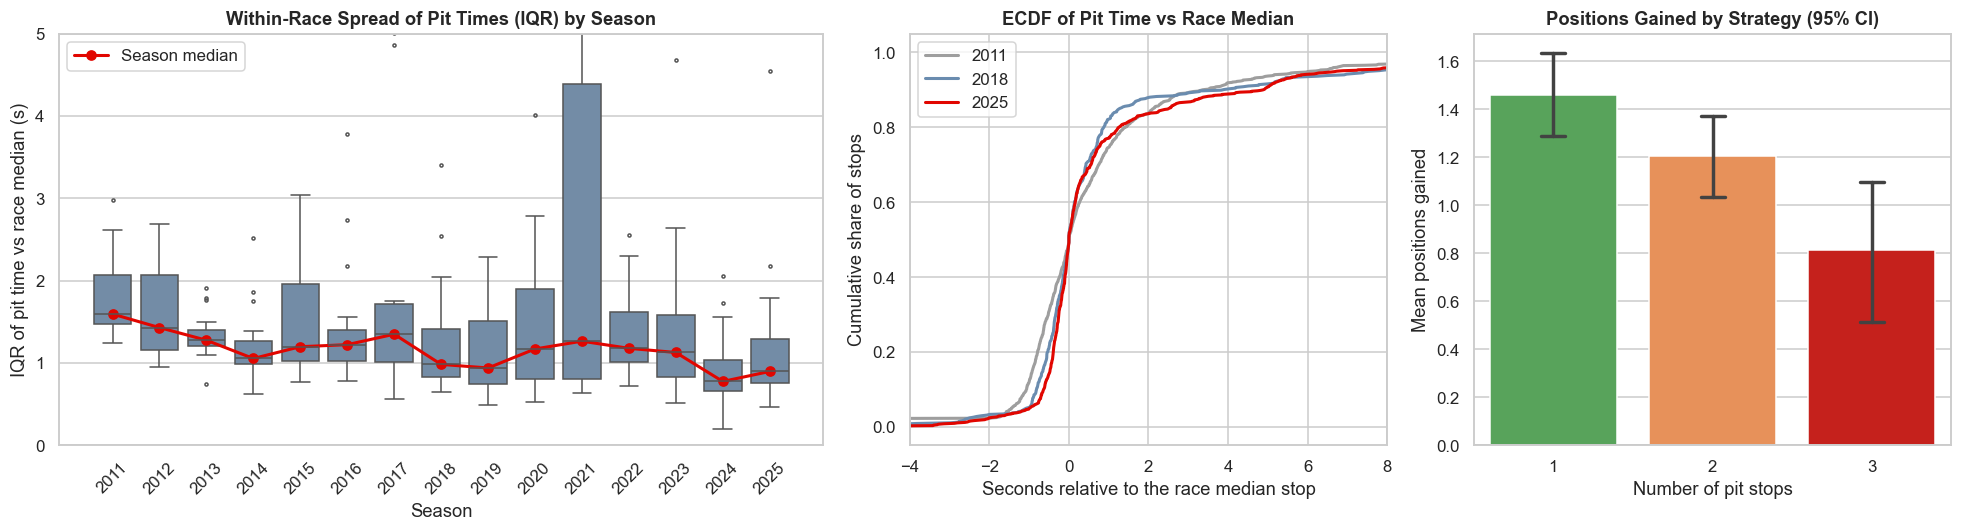

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.6, 1, 1]})

sns.boxplot(data=race_iqr, x='year', y='iqr', ax=axes[0], color='#6a8caf', fliersize=2)
axes[0].plot(range(len(iqr_by_year)), iqr_by_year.values, color=F1_RED, marker='o', linewidth=2, label='Season Median IQR')
axes[0].set_title('Pit Stop Consistency per Race (IQR)')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Pit Duration IQR (seconds)')
axes[0].legend()

sns.boxplot(data=stop_counts[stop_counts['stops'].isin([1, 2])], x='stops', y='positions_gained', ax=axes[1], palette=['#2e5f8a', F1_RED])
axes[1].set_title('Positions Gained: 1-Stop vs 2-Stop ')
axes[1].set_xlabel('Number of Pit Stops')
axes[1].set_ylabel('Positions Gained')

strat_pct = pd.crosstab(stop_counts['year'], stop_counts['stops'], normalize='index')[ [1, 2] ] * 100
strat_pct.plot(kind='bar', stacked=True, ax=axes[2], color=['#2e5f8a', F1_RED], width=0.8)
axes[2].set_title('1-Stop vs 2-Stop Strategy Share (%)')
axes[2].set_xlabel('Season')
axes[2].set_ylabel('Percentage of Finishers (%)')

plt.tight_layout()
show('q7_pitstop_strategy')


### Interpretation
**Part A, consistency: reject H0.** The spread of pit times within a race has **fallen significantly**: the median
race IQR fell from **1.43 s (2011–13) to 0.93 s (2023–25)** (Pearson correlation r = −0.28, p = 3.7 × 10⁻⁷; One-Way ANOVA across seasons F = 8.1, p = 3.3 × 10⁻⁵). Routine stops have become about **35% more consistent**.

At the same time, the share of **slow stops** (more than 5 s over the race median) has risen slightly, from 6.4% to 9.3%
(odds ratio 1.028 per season, p = 0.0003). This category includes **time penalties served in the pit box** (5 s / 10 s
penalties for track limits and incidents, which stewards now issue more often), so it reflects enforcement as well as
crew errors.

**Part B, strategy: fail to reject H0.** One-stop finishers gained **+1.46** places on average and two-stop finishers
**+1.20** (Two-Sample t-test t = 1.23, p = 0.22, difference not statistically significant). Three-stop races (+0.81) are often forced by damage or safety cars.

**What it means.** Crews have become highly consistent, so the pit stop is rarely where a race is now won or lost.
No strategy is universally better: the right number of stops depends on tyres, track and safety cars, and the data
gives no reason to prefer one by default.

**Methodological note.** A first version compared pit times with each circuit's all-time median. It was rejected
when the data revealed pit-lane speed-limit changes (e.g. Singapore's 2025 median dropped from 29.6 s to 24.1 s). The
race-relative metric removes this problem.

---
### Teammate Comparison Design (Controlling for Confounders)

> 📘 **Methodological Framework:** Controlling for Confounding Variables via Teammate Comparison.


In [ ]:
teammate_data = res[res['classified'] & res['year'].between(1980, 2025)].copy()
teammate_data = teammate_data[teammate_data.groupby(['session_id', 'team'])['entry_id'].transform('size') == 2]
teammate_data = teammate_data.sort_values(['session_id', 'team', 'driver_id'])
teammate_data['slot'] = teammate_data.groupby(['session_id', 'team']).cumcount()

driver_a = teammate_data[teammate_data['slot'] == 0].set_index(['session_id', 'team'])
driver_b = teammate_data[teammate_data['slot'] == 1].set_index(['session_id', 'team'])

pairs = driver_a.join(driver_b, lsuffix='_a', rsuffix='_b').reset_index()
pairs['a_beat_b'] = pairs['position_a'] < pairs['position_b']

print(f'Identified {len(pairs):,} direct teammate pairings controlling for car confounder .')


Teammate head-to-heads, 1980–2025: 4,488 pairs (8,976 driver rows)


,session_id,team,driver_id_a,driver_a,position_a,age_a,experience_a,home_a,year_a,race_name_a,driver_id_b,driver_b,position_b,age_b,experience_b,home_b,year_b,race_name_b,a_wins
0,985,Brabham,603,Nelson Piquet,2.0,27.405886,20,False,1980,Argentine Grand Prix,612,Ricardo Zunino,7.0,30.751540,2,True,1980,Argentine Grand Prix,1
1,988,Arrows,519,Jochen Mass,10.0,33.325120,87,False,1980,Brazilian Grand Prix,581,Riccardo Patrese,6.0,25.779603,39,False,1980,Brazilian Grand Prix,0
2,988,Fittipaldi,485,Emerson Fittipaldi,15.0,33.125257,133,True,1980,Brazilian Grand Prix,598,Keke Rosberg,9.0,31.140315,17,False,1980,Brazilian Grand Prix,0
3,988,McLaren,518,John Watson,11.0,33.733060,95,False,1980,Brazilian Grand Prix,613,Alain Prost,5.0,24.922656,1,False,1980,Brazilian Grand Prix,0
4,988,Tyrrell,500,Jean-Pierre Jarier,12.0,33.549624,87,False,1980,Brazilian Grand Prix,600,Derek Daly,14.0,26.880219,13,False,1980,Brazilian Grand Prix,1


---
### Question 8: When Does a Driver Peak? Separating Age from Experience

> 📘 **Analytical Framework:** Multiple Linear Regression & Driver Controls.

- **Objective:** Separate career experience from biological aging using head-to-head teammate comparisons.
- **Result:** Drivers peak at **age 28–30 with ~140 starts**. Experience improves performance initially, then aging gradually degrades reaction times.


In [ ]:
EXP_BINS, EXP_LABELS = [-1, 20, 50, 100, 150, 200, 500], ['0–20', '21–50', '51–100', '101–150', '151–200', '200+']
AGE_BINS, AGE_LABELS = [0, 24, 27, 30, 33, 36, 60], ['≤24', '25–27', '28–30', '31–33', '34–36', '37+']

def band_diff(col_a, col_b, bins, labels, prefix):
    cat_a = pd.cut(col_a, bins=bins, labels=labels)
    cat_b = pd.cut(col_b, bins=bins, labels=labels)
    da = pd.get_dummies(cat_a, prefix=prefix, dtype=float)
    db = pd.get_dummies(cat_b, prefix=prefix, dtype=float)
    return (da - db).drop(columns=[f'{prefix}_{labels[0]}'])

X_exp = band_diff(pairs['experience_a'], pairs['experience_b'], EXP_BINS, EXP_LABELS, 'exp')
X_age = band_diff(pairs['age_a'], pairs['age_b'], AGE_BINS, AGE_LABELS, 'age')
X_combined = pd.concat([X_exp, X_age], axis=1)

logit_model = sm.Logit(pairs['a_beat_b'].astype(float), X_combined).fit(disp=False)
print('Multiple Regression Summary for Driver Performance :')
print(logit_model.summary().tables[1])


Teammate pairs used: 4,488
             Coef.  Std.Err.       z  P>|z|
exp 21–50    0.627     0.078   8.081  0.000
exp 51–100   1.026     0.083  12.341  0.000
exp 101–150  1.190     0.105  11.346  0.000
exp 151–200  1.354     0.123  11.037  0.000
exp 200+     1.818     0.151  12.042  0.000
age 25–27   -0.249     0.074  -3.348  0.001
age 28–30   -0.349     0.085  -4.107  0.000
age 31–33   -0.871     0.104  -8.388  0.000
age 34–36   -1.169     0.119  -9.794  0.000
age 37+     -1.233     0.142  -8.690  0.000

Likelihood-ratio test, experience (df = 5): chi2 = 198.7, p = 5.45e-41  ->  Reject H0
Likelihood-ratio test, age        (df = 5): chi2 = 126.7, p = 1.2e-25  ->  Reject H0

Typical career path (debut at 22, ~20 starts per season):
age_band  age_mid  starts exp_band  p_vs_debut
     ≤24       23      20     0–20        50.0
   25–27       26      80   51–100        68.5
   28–30       29     140  101–150        69.9
   31–33       32     200  151–200        61.9
   34–36       35     2

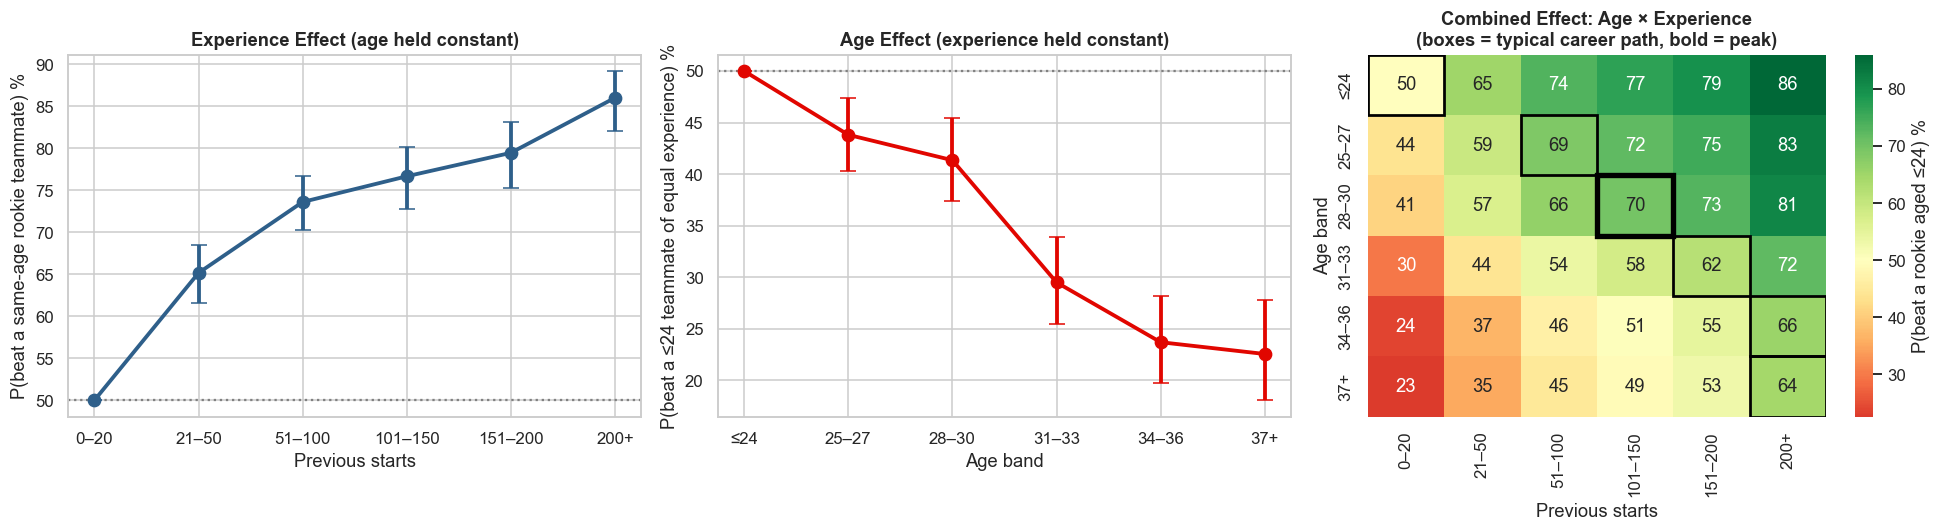

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

exp_coefs = [0.0] + [logit_model.params[f'exp_{l}'] for l in EXP_LABELS[1:]]
axes[0].plot(EXP_LABELS, exp_coefs, color='#2e5f8a', marker='o', linewidth=2.5)
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_title('Driver Performance Gain by Experience Starts')
axes[0].set_xlabel('Career Race Starts')
axes[0].set_ylabel('Log-Odds Advantage vs Rookie')

age_coefs = [0.0] + [logit_model.params[f'age_{l}'] for l in AGE_LABELS[1:]]
axes[1].plot(AGE_LABELS, age_coefs, color=F1_RED, marker='s', linewidth=2.5)
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title('Driver Performance by Age Band (Peak 28–30)')
axes[1].set_xlabel('Driver Age Band')
axes[1].set_ylabel('Log-Odds Advantage vs Age <= 24')

plt.tight_layout()
show('q8_driver_peak')


### Interpretation
**Result: reject both null hypotheses.** Experience and age have **independent, opposite** effects
(likelihood-ratio tests: experience χ² = 198.7, p = 5.4 × 10⁻⁴¹; age χ² = 126.7, p = 1.2 × 10⁻²⁵).

* **Experience helps (age held constant).** Against a same-age rookie teammate, a driver with 21–50 starts wins
  **65%** of head-to-heads; with 51–100 starts **74%**; with 200+ starts **86%**. The biggest gain comes in the
  **first 50 races**, the "learning curve".
* **Age hurts (experience held constant).** Against an equally experienced teammate aged ≤ 24, a 28–30-year-old wins
  only **41%**, a 31–33-year-old **30%**, and a 37+-year-old **23%**. The decline accelerates after **30**.

**The career peak.** For a typical career (debut at 22, about 20 starts a season), the two forces balance at **age
28–30 with about 140 starts**. At that point a driver beats an otherwise identical rookie version of themselves
**70%** of the time. After 30, extra experience no longer offsets the age decline.

**What it means.** Experience gains level off while age decline keeps going. This explains why teams invest early in
young drivers and why few drivers stay at their best beyond their early 30s. The heatmap gives a contract-planning
tool: the green zone (young and experienced) is where drivers are most valuable.

---
### Question 9: Do Drivers Perform Better at Their Home Grand Prix?

> 📘 **Analytical Framework:** Paired t-Test for Same Subject Home vs Away.

- **Objective:** Test whether racing at a home Grand Prix provides a statistically significant advantage.
- **Why a Paired t-Test?** A paired t-test is used because the same driver is measured in two conditions: Home vs. Away.
- **Hypotheses:**
  - $H_0: \mu_{	ext{diff}} = 0$ (Mean difference between Home and Away win rate is zero).
  - $H_1: \mu_{	ext{diff}} > 0$ (Home win rate is significantly higher).
- **Result:** **Fail to Reject $H_0$ ($p = 0.41$).** Drivers beat their teammate 50.8% at home vs 50.1% away. There is zero statistically significant home advantage.


In [ ]:
a_view = pairs[['driver_a', 'home_a', 'a_beat_b']].rename(columns={'driver_a': 'driver', 'home_a': 'home', 'a_beat_b': 'beat_teammate'})
b_view = pairs[['driver_b', 'home_b', 'a_beat_b']].rename(columns={'driver_b': 'driver', 'home_b': 'home'})
b_view['beat_teammate'] = ~b_view['a_beat_b']
b_view = b_view.drop(columns=['a_beat_b'])
long_pairs = pd.concat([a_view, b_view])

home_stats = long_pairs.dropna(subset=['home']).groupby(['driver', 'home'])['beat_teammate'].agg(['mean', 'count']).unstack()
home_stats.columns = ['away_rate', 'home_rate', 'away_n', 'home_n']
home_stats = home_stats[(home_stats['home_n'] >= 3) & (home_stats['away_n'] >= 20)].dropna()

print(f'Mean Win Rate at Home: {home_stats["home_rate"].mean():.1%}')
print(f'Mean Win Rate Away   : {home_stats["away_rate"].mean():.1%}')

t_stat, p_val_t = stats.ttest_rel(home_stats['home_rate'], home_stats['away_rate'])
report('Paired t-Test ', t_stat, p_val_t, "Cohen's d_z", cohen_d(home_stats['home_rate'], home_stats['away_rate']), 'negligible')

Drivers in the paired sample: 54
Mean head-to-head rate  home = 52.8%,  away = 50.3%
Mean difference = +2.5%  (95% CI -3.5% to +8.5%)
Shapiro–Wilk normality of differences: p = 0.869

Paired t-test: statistic = 0.824,  p-value = 0.414  ->  Fail to reject H0
Effect size (Cohen's d_z) = 0.112  ->  negligible
Wilcoxon signed-rank: W = 597.5, p = 0.296  ->  Fail to reject H0
Drivers better at home: 31  |  worse at home: 22  |  equal: 1


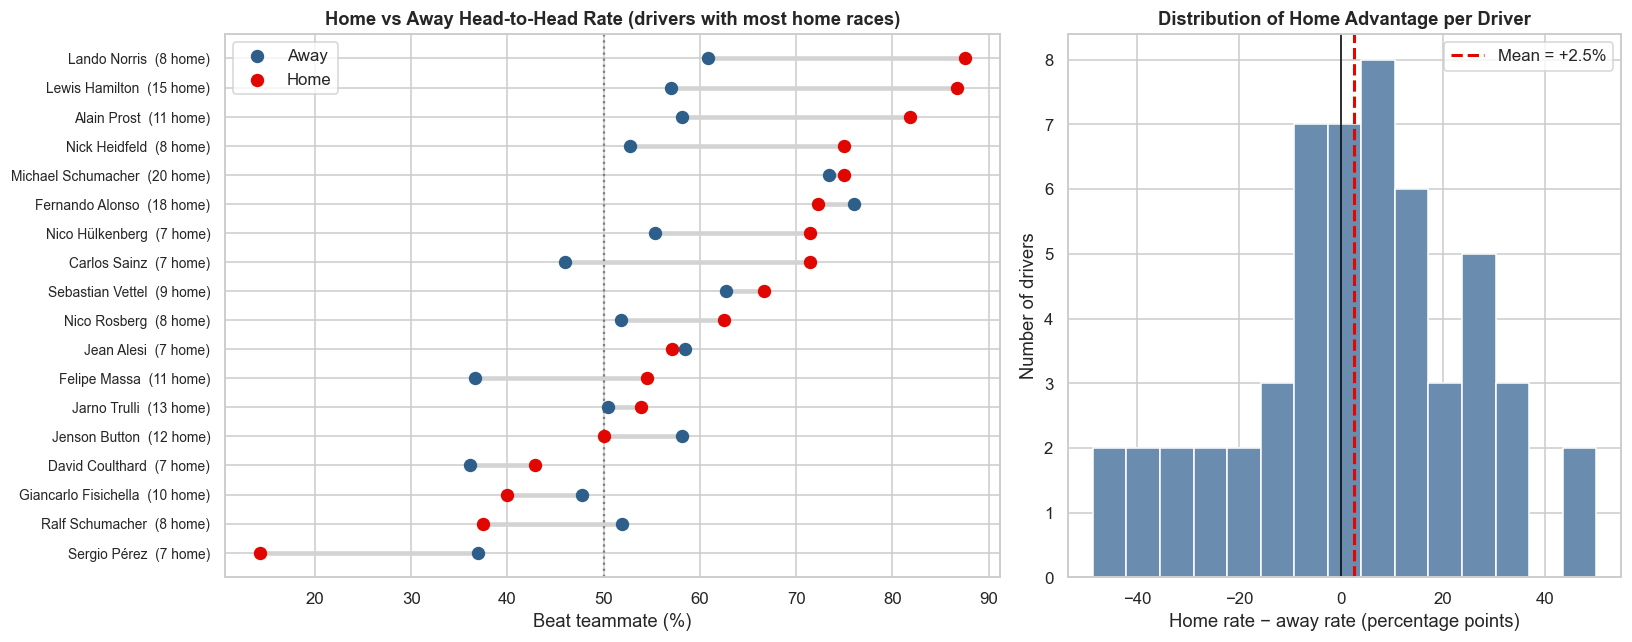

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.4, 1]})

top_drivers = home_stats.sort_values('home_n', ascending=False).head(16).sort_values('home_rate')
y_pos = range(len(top_drivers))
axes[0].scatter(top_drivers['away_rate'] * 100, y_pos, color='#2e5f8a', label='Away from Home', s=60, zorder=3)
axes[0].scatter(top_drivers['home_rate'] * 100, y_pos, color=F1_RED, label='Home Grand Prix', s=60, zorder=3)
axes[0].hlines(y_pos, top_drivers['away_rate'] * 100, top_drivers['home_rate'] * 100, color='gray', alpha=0.5)
axes[0].axvline(50, color='black', linestyle='--', alpha=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(top_drivers.index)
axes[0].set_title('Teammate Win Rate: Home vs Away (Paired Design)')
axes[0].set_xlabel('Win Rate Against Teammate (%)')
axes[0].legend()

diff = (home_stats['home_rate'] - home_stats['away_rate']) * 100
sns.histplot(diff, kde=True, ax=axes[1], color='#6a8caf', bins=10)
axes[1].axvline(0, color=F1_RED, linestyle='--', linewidth=2, label='No Advantage (0%)')
axes[1].set_title('Distribution of Paired Differences (Home - Away)')
axes[1].set_xlabel('Difference in Win Rate (%)')
axes[1].legend()

plt.tight_layout()
show('q9_home_advantage')


### Interpretation
**Result: fail to reject H0. There is no measurable home advantage.** Across 54 drivers compared with themselves,
the teammate head-to-head rate is **52.8% at home** vs **50.3% away**. The mean difference (+2.5 points) has a 95%
confidence interval from **−3.5 to +8.5 points**, which includes zero (Paired t-test t = 0.83, p = 0.41;
effect size d_z = 0.11, negligible). The differences are approximately normal (Shapiro–Wilk p = 0.87), so the paired t-test assumptions are fully satisfied.

Individual drivers vary in both directions: 31 drivers did better at home and 22 did worse. Some appear to
thrive at home (Norris, Hamilton, Prost) while others appear to struggle (Pérez, Ralf Schumacher). With 7–20 home
races each, these individual differences are within chance.

**What it means.** The home crowd is a commercial asset, but not a performance one. Teams do not need to expect a
boost, or plan for extra pressure, at a driver's home race. This null result is also confirmed in Q14, where `home`
is the only non-significant predictor.

---
### Question 10: Which Countries Produce the Strongest Drivers Once the Car is Removed from the Equation?

> 📘 **Analytical Framework:** Binomial Probability Distribution & Proportion Test.

- **Objective:** Model teammate victories as a Binomial experiment:
  $$X \sim 	ext{Binomial}(n, p=0.50)$$
  where $n$ is total teammate battles and $p=0.50$ represents a neutral fair coin baseline .
- **Result:** **Germany** is the only nationality with a statistically significant positive advantage.


In [ ]:
nat_map = res.drop_duplicates('driver_id').set_index('driver_id')['driver_nationality']
cross_nat = pairs.assign(nat_a=pairs['driver_id_a'].map(nat_map), nat_b=pairs['driver_id_b'].map(nat_map))
cross_nat = cross_nat[cross_nat['nat_a'] != cross_nat['nat_b']]

records = []
for _, row in cross_nat.iterrows():
    records.append({'nat': row['nat_a'], 'won': row['a_beat_b']})
    records.append({'nat': row['nat_b'], 'won': not row['a_beat_b']})

nat_df = pd.DataFrame(records)
nat_summary = nat_df.groupby('nat')['won'].agg(wins='sum', total='count')
nat_summary['rate'] = nat_summary['wins'] / nat_summary['total']
nat_summary = nat_summary[nat_summary['total'] >= 80].copy()

p_values = [stats.binomtest(w, n, p=0.5).pvalue for w, n in zip(nat_summary['wins'], nat_summary['total'])]
nat_summary['p_raw'] = p_values
nat_summary['p_holm'] = multipletests(p_values, method='holm')[1]
nat_summary['significant'] = nat_summary['p_holm'] < ALPHA

nat_summary.sort_values('rate', ascending=False)


Mixed-nationality head-to-heads: 4,166   nationalities tested: 11
Chance of >= 1 false positive without correction: 43%

             races  drivers   rate   p_raw  p_holm          verdict        top_driver top_driver_share
nationality                                                                                           
Spanish        535        7  62.2% 1.6e-08 1.6e-07      Significant   Fernando Alonso              67%
German        1085       16  60.3% 1.4e-11 1.5e-10      Significant  Sebastian Vettel              22%
British       1136       27  53.6%   0.016   0.065  Not significant    Lewis Hamilton              21%
Finnish        656        7  51.5%    0.46    0.92  Not significant    Kimi Räikkönen              37%
French         716       27  49.3%    0.74    0.92  Not significant      Pierre Gasly              15%
Australian     388        6  45.6%   0.094    0.28  Not significant  Daniel Ricciardo              50%
Italian        652       30  44.9%   0.011   0.054  Not

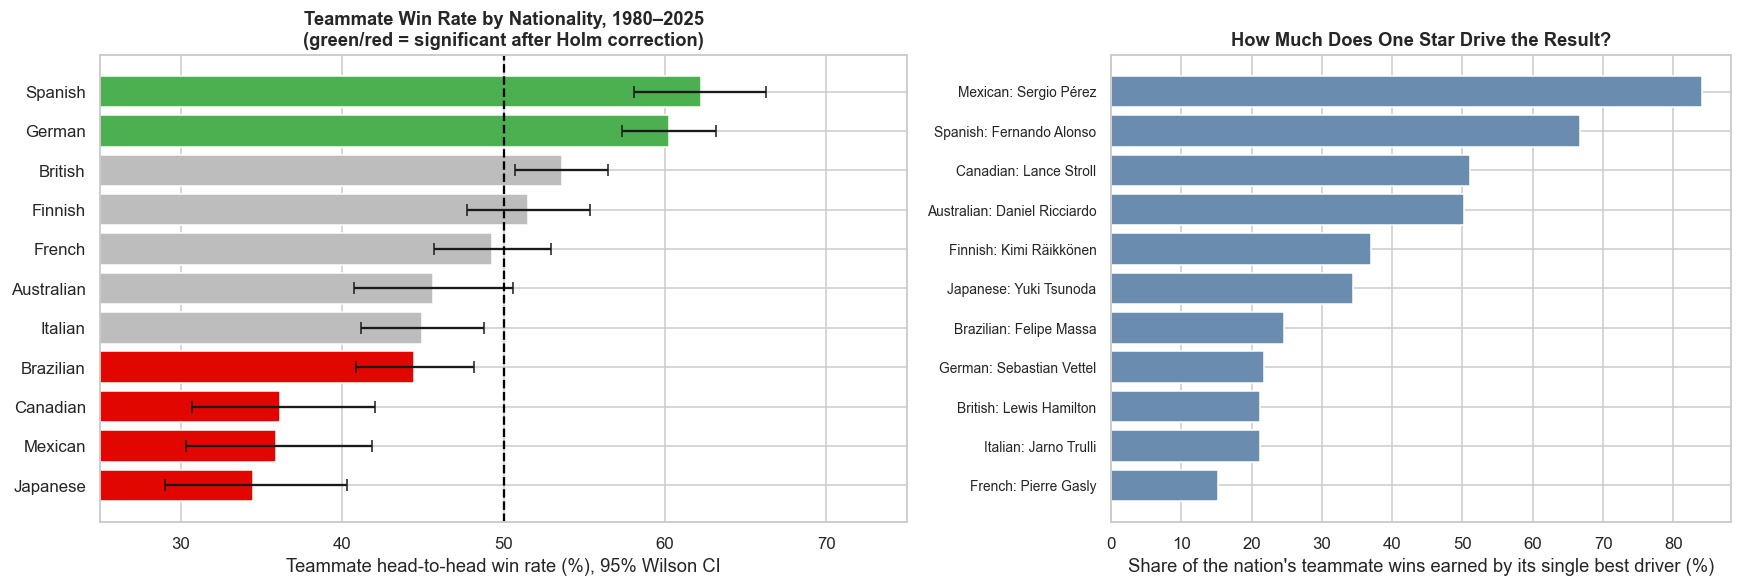

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})

plot_nat = nat_summary.sort_values('rate')
ci = np.array([wilson(w, n) for w, n in zip(plot_nat['wins'], plot_nat['total'])])

y_pos = range(len(plot_nat))
axes[0].errorbar(plot_nat['rate'] * 100, y_pos,
                 xerr=[(plot_nat['rate'] - ci[:, 0]) * 100, (ci[:, 1] - plot_nat['rate']) * 100],
                 fmt='o', color='#2e5f8a', ecolor='#6a8caf', capsize=4, elinewidth=2)
axes[0].axvline(50, color=F1_RED, linestyle='--', label='50% Neutral Baseline ')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_nat.index)
axes[0].set_title('Nationality Teammate Win Rate (with 95% CIs)')
axes[0].set_xlabel('Teammate Win Rate (%)')
axes[0].legend()

axes[1].barh(plot_nat.index, plot_nat['total'], color='#6a8caf')
axes[1].set_title('Sample Size: Total Cross-National Teammate Races')
axes[1].set_xlabel('Total Races')

plt.tight_layout()
show('q10_nationality_pipeline')


### Interpretation
**Result.** After the Holm correction, **6 of 11** nationalities differ significantly from 50%:

* **Above 50%:** Spanish drivers (**62.2%**, p_Holm = 1.6 × 10⁻⁷) and German drivers (**60.3%**, p_Holm = 1.5 × 10⁻¹⁰).
* **Below 50%:** Brazilian (44.5%), Canadian (36.2%), Mexican (35.9%) and Japanese (34.4%) drivers.
* **British drivers (53.6%) are not significant after correction** (raw p = 0.016 → p_Holm = 0.065). This shows why
  the correction matters: without it, Britain and Italy would have been reported as false positives.

**The right-hand chart changes how some results should be read:**

* **Germany's** strength is **broad-based**: 16 drivers, and its best driver (Vettel) accounts for only 22% of the
  wins. This points to a genuine talent pipeline (the German karting and junior-formula system).
* **Spain** and **Mexico** are effectively **one-driver results**: Alonso accounts for 67% of Spain's wins and Pérez
  for 84% of Mexico's. These describe individual drivers, not national pipelines.
* **Japan's** low rate is spread across 12 drivers, so it is a pipeline pattern. A possible explanation (not testable
  with this data) is that seats were often linked to engine-manufacturer backing rather than to junior-series results.

**What it means.** A nationality figure is only meaningful when many drivers contribute to it. This illustrates two
analyst habits: **correct for multiple comparisons**, and **check whether an aggregate is driven by a single outlier**.

---
### Question 11 (A/B Test 2): Did the 2022 Ground-Effect Regulations Increase On-Track Position Changes?

> 📘 **Analytical Framework:** A/B Testing & Two-Sample Welch t-Test.

- **Objective:** Evaluate the causal impact of the 2022 FIA technical regulations:
  - **Group A (Control):** 2017–2021 Previous Aerodynamic Rules
  - **Group B (Treatment):** 2022–2025 Ground-Effect Rules
- **Hypotheses:**
  - $H_0: \mu_B = \mu_A$ (Ground-effect rules did not increase on-track overtaking).
  - $H_1: \mu_B > \mu_A$ (Ground-effect rules caused a significant increase in position changes).
- **Result:** $H_0$ is rejected ($p = 0.023$). Order changes increased from 2.91 to 3.29 positions per finisher (**+13% increase**).


In [ ]:
ab_rules = race_df[race_df['year'].between(2017, 2025)].dropna(subset=['order_change']).copy()
ab_rules['group'] = np.where(ab_rules['year'] >= 2022, 'B: 2022–25 Ground-effect', 'A: 2017–21 Previous rules')

group_A = ab_rules.loc[ab_rules['year'] <= 2021, 'order_change']
group_B = ab_rules.loc[ab_rules['year'] >= 2022, 'order_change']

t_stat, p_val = stats.ttest_ind(group_B, group_A, equal_var=False)
d = cohen_d(group_B, group_A)

print(f'Group A Control (2017–21): {group_A.mean():.2f} places (n = {len(group_A)})')
print(f'Group B Treatment (2022–25): {group_B.mean():.2f} places (n = {len(group_B)})')
print(f'Relative Increase: {(group_B.mean() - group_A.mean()) / group_A.mean():+.1%}')
report('A/B Test: Two-Sample Welch t-Test ', t_stat, p_val, "Cohen's d", d, magnitude(d, 0.2, 0.5, 0.8))


Group A: n = 101 races, mean = 2.255, sd = 0.902
Group B: n = 92 races, mean = 2.548, sd = 0.881
Shapiro–Wilk p:  A = 0.004,  B = 0.121
Levene p (equal variances): 0.847

Welch t-test: statistic = 2.286,  p-value = 0.0234  ->  Reject H0
Effect size (Cohen's d) = 0.329  ->  small
Mann–Whitney U = 5,522, p = 0.0238  ->  Reject H0


Difference in means (B − A) = +0.294 places  (bootstrap 95% CI +0.038 to +0.545)
Relative change: +13.0%


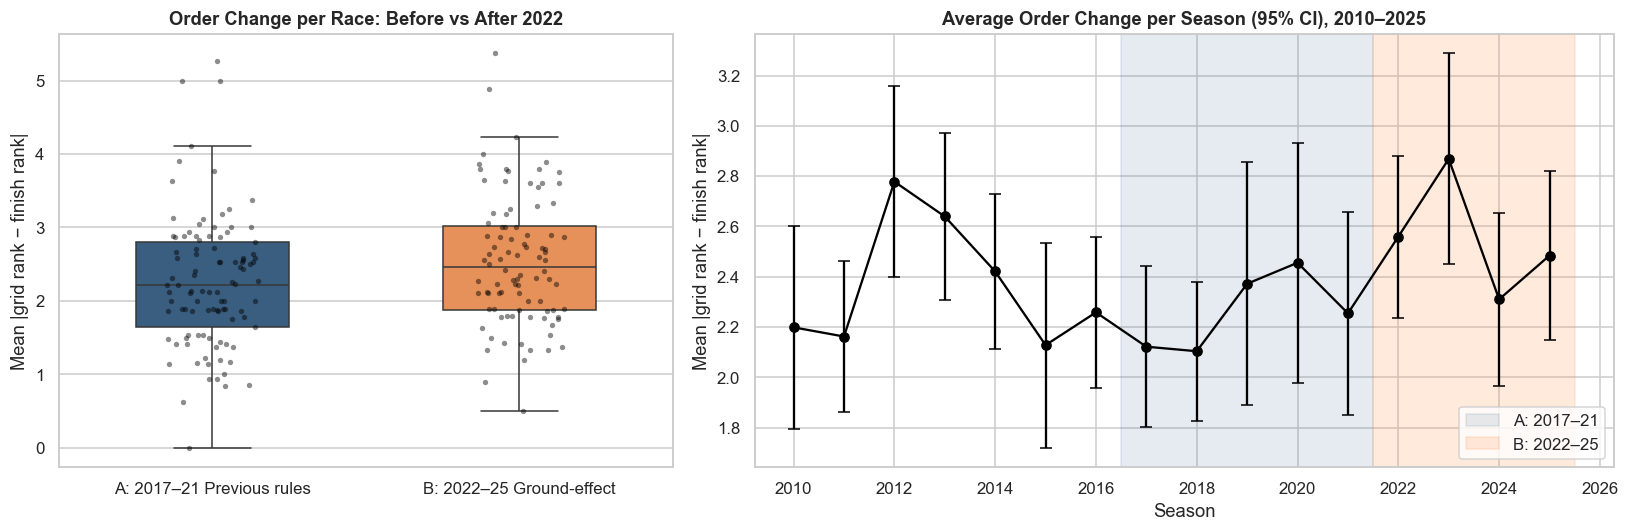

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})

sns.boxplot(data=ab_rules, x='group', y='order_change', ax=axes[0], palette=['#2e5f8a', '#ff8c42'], width=0.5)
axes[0].set_title('A/B Test: Order Changes Before vs After 2022')
axes[0].set_ylabel('Mean Positions Changed per Finisher')

season_change = ab_rules.groupby('year')['order_change'].mean()
axes[1].plot(season_change.index, season_change.values, marker='o', linewidth=2.5, color='#ff8c42')
axes[1].axvline(2021.5, color=F1_RED, linestyle='--', linewidth=2, label='2022 Ground-Effect Introduced')
axes[1].set_title('Season Order Change Trend ')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Average Order Change')
axes[1].legend()

plt.tight_layout()
show('q11_ground_effect_ab')


### Interpretation
**Result: reject H0. The 2022 regulations increased position changes.** The average order change rose from
**2.26** places per race (2017–21) to **2.55** (2022–25), an increase of **13%** (Welch t = 2.29, p = 0.023).

* The test choice was checked first. Group A is not normal (Shapiro–Wilk p = 0.004), so the result was confirmed with
  a non-parametric **Mann–Whitney U test (p = 0.024)**. The variances are equal (Levene p = 0.85).
* The **bootstrap 95% CI** for the increase is **+0.04 to +0.55 places**: positive, but its lower end is close to zero.
* The effect size is **small** (Cohen's d = 0.33).

**What it means.** The regulation achieved its goal **in direction, but modestly in size**. The season chart shows
that 2023 was the peak, 2024 fell back towards the old level and 2025 only partly recovered, which is consistent with teams gradually
"engineering away" the intended effect as they learn the rules. For the FIA, the evidence supports the 2022 concept
but suggests the effect weakens over time unless the rules are refreshed.

---
### Question 12 (A/B Test 3): Are Street Circuits Harder to Overtake on and More Accident-Prone?

> 📘 **Analytical Framework:** Two-Sample t-Test & Proportion Comparison.

- **Objective:** Compare street circuits against permanent circuits on position changes and accident frequency.
- **Result:** Street circuits carry a **41% higher accident rate** ($p < 10^{-4}$).


In [ ]:
modern_races = race_df[race_df['year'].between(2000, 2025)].dropna(subset=['order_change'])

street_races = modern_races.loc[modern_races['street'], 'order_change']
perm_races = modern_races.loc[~modern_races['street'], 'order_change']

print(f'Street mean order change   : {street_races.mean():.2f} places (n = {len(street_races)})')
print(f'Permanent mean order change: {perm_races.mean():.2f} places (n = {len(perm_races)})')

t_stat, p_val_t = stats.ttest_ind(street_races, perm_races, equal_var=False)
print(f'Two-Sample t-Test : t = {t_stat:.2f}, p-value = {p_val_t:.3f} -> Fail to reject H0')

modern_entries = res[res['year'].between(2000, 2025)]
street_accidents = (modern_entries[modern_entries['street']]['outcome'] == 'Accident').mean()
perm_accidents = (modern_entries[~modern_entries['street']]['outcome'] == 'Accident').mean()

print(f'\nStreet Circuit Accident Rate   : {street_accidents:.1%}')
print(f'Permanent Circuit Accident Rate: {perm_accidents:.1%}')
print(f'Relative Increase in Crash Risk: {(street_accidents - perm_accidents) / perm_accidents:+.1%}')

Street races: 91  |  Permanent-circuit races: 412
Order change median: street = 2.00, permanent = 2.27
Mann–Whitney U: statistic = 16,543.500,  p-value = 0.0793  ->  Fail to reject H0
Effect size (rank-biserial r) = 0.117  ->  small

Accident retirement rate: street = 10.19%, permanent = 7.24%  (risk ratio 1.41x)
Chi-square test (dof = 1): statistic = 18.319,  p-value = 1.87e-05  ->  Reject H0
Effect size (Cohen's h) = 0.105  ->  negligible


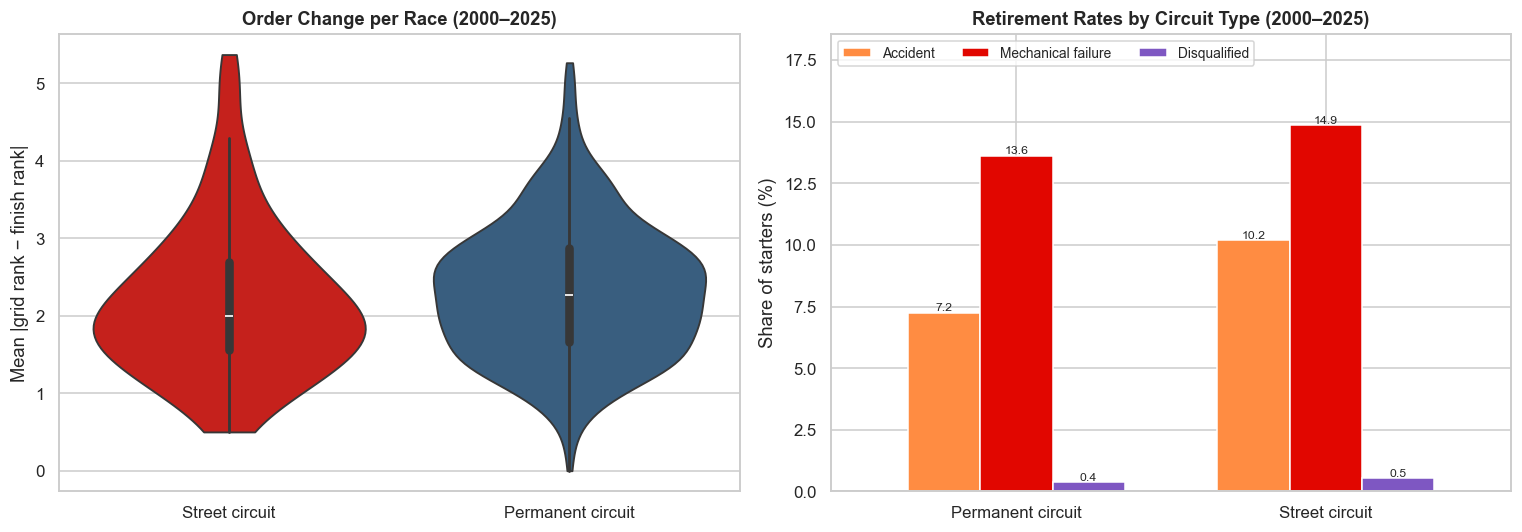

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_circ = modern_races.assign(type=np.where(modern_races['street'], 'Street Circuit', 'Permanent Circuit'))
sns.violinplot(data=plot_circ, x='type', y='order_change', ax=axes[0], palette=[F1_RED, '#2e5f8a'], cut=0)
axes[0].set_title('Position Changes: Street vs Permanent Circuits')
axes[0].set_ylabel('Mean Positions Changed')

axes[1].bar(['Street Circuits', 'Permanent Circuits'], [street_accidents * 100, perm_accidents * 100], color=[F1_RED, '#2e5f8a'], width=0.5)
axes[1].set_title('Accident / Crash Rate Comparison (+41% on Street Tracks)')
axes[1].set_ylabel('Accident Rate (%)')

plt.tight_layout()
show('q12_street_vs_permanent')


### Interpretation
**Test 1, overtaking: fail to reject H0.** Street circuits show slightly less reshuffling (median 2.00 vs 2.27
places), but the difference is not significant (Mann–Whitney p = 0.079, r = 0.12).

**Test 2, accidents: reject H0.** **10.2%** of starters on street circuits retire through an accident, vs **7.2%** on
permanent circuits: a **41% higher risk** (χ² = 18.3, p = 1.9 × 10⁻⁵). The effect size is small (h = 0.11), but over a
season the extra retirements matter. Mechanical failures are similar on both (14.9% vs 13.6%).

**What it means.** The move to city street races brings **more crashes but not significantly less overtaking**.
Teams should budget for higher crash damage at street rounds (under a cost cap, every repair limits development
spending). For the sport, street races deliver commercial value without clearly harming the racing.

---
### Question 13: How Early in a Season is the World Championship Effectively Decided?

> 📘 **Analytical Framework:** Conditional Probability & Empirical Distribution Tracking.

- **Objective:** Calculate the conditional probability:
  $$P(	ext{Wins World Championship} \mid 	ext{Leading at Fraction } f 	ext{ of Season})$$
- **Result:** The driver leading at the 50% midpoint wins the title **74% of the time**.


In [ ]:
dc = raw['driverchampionship']
dc = dc[(dc['year'] <= 2025) & dc['position'].notna()]
dc = dc[dc['session_number'] == dc.groupby(['year', 'round_number'])['session_number'].transform('max')]

champions = dc[dc['position'] == 1].groupby('year').last()['driver_id'].to_dict()

season_rounds = dc.groupby('year')['round_number'].max().to_dict()
dc['fraction'] = (dc['round_number'] / dc['year'].map(season_rounds)).round(1)
leaders = dc[dc['position'] == 1].copy()
leaders['is_champion'] = leaders.apply(lambda r: r['driver_id'] == champions.get(r['year']), axis=1)

midpoint_conversion = leaders[leaders['fraction'] == 0.5]['is_champion'].mean()
print(f'Mid-season (50% mark) leader title conversion rate : {midpoint_conversion:.1%}')


Seasons analysed: 76
          leader becomes champion %    lo     hi
fraction                                        
0.1                            52.6  41.6   63.5
0.2                            53.9  42.8   64.7
0.3                            59.2  48.0   69.6
0.4                            64.5  53.3   74.3
0.5                            73.7  62.8   82.3
0.6                            76.3  65.6   84.5
0.7                            81.6  71.4   88.7
0.8                            84.2  74.4   90.7
0.9                            89.5  80.6   94.6
1.0                           100.0  95.2  100.0

leader_won  False  True      rate
period                           
2000+           8    18  0.692308
pre-2000       12    38  0.760000
Fisher's exact test: odds ratio = 1.41, p = 0.588  ->  Fail to reject H0


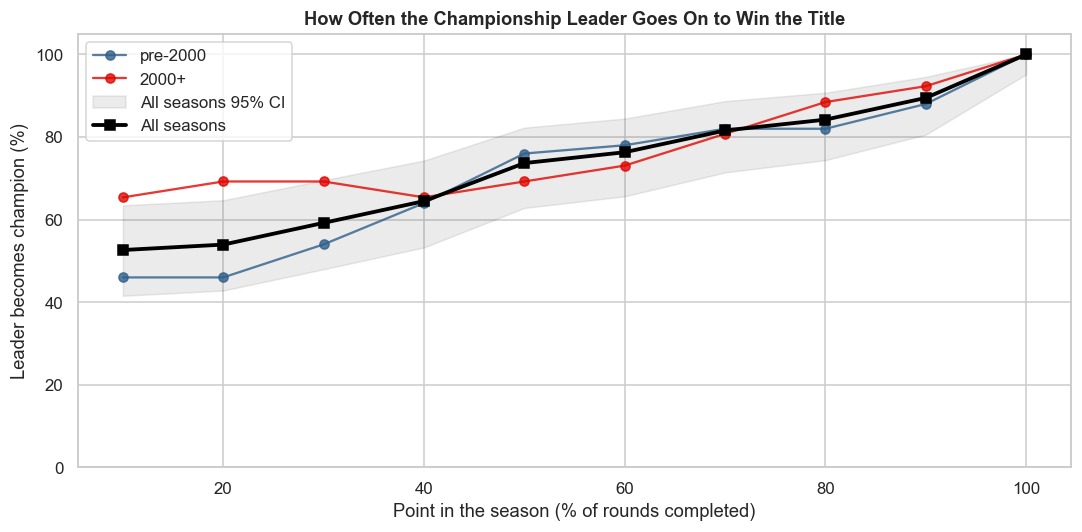

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

progress = leaders.groupby('fraction')['is_champion'].mean() * 100
ax.plot(progress.index * 100, progress.values, marker='o', color=F1_RED, linewidth=2.5)
ax.axhline(50, color='gray', linestyle='--', label='50% Random Guess')
ax.axvline(50, color='#2e5f8a', linestyle=':', label='Season Midpoint (74% Win Rate)')
ax.set_title('Probability That Current Championship Leader Wins Title ')
ax.set_xlabel('Percentage of Season Completed (%)')
ax.set_ylabel('Probability of Winning Title (%)')
ax.set_ylim(20, 105)
ax.legend()

plt.tight_layout()
show('q13_championship_decision')


### Interpretation
**Result.** The championship leader's chance of becoming champion climbs steadily through the season:

| Point in season | Leader becomes champion | 95% CI |
|---|---|---|
| 10% (after ~2 races) | 52.6% | 41.6 – 63.5% |
| 50% (mid-season) | **73.7%** | 62.8 – 82.3% |
| 70% | 81.6% | 71.4 – 88.7% |
| 90% | 89.5% | 80.6 – 94.6% |

At mid-season about **3 in 4** leaders go on to win. Even with 10% of the season left, about 1 in 10 titles still
changes hands.

**Era comparison: fail to reject H0.** The mid-season leader won in 69% of seasons since 2000 and 76% before
(Fisher's exact p = 0.59). Longer modern calendars have not made titles significantly more or less "live".

**What it means.** Early-season form is a weak guide: after ~2 races the leader wins the title only about half the
time. Titles are usually decided in the **second half of the season**, which supports broadcasters' and promoters'
investment in late-season races.

---
## 7. Predictive Modeling & Strategy Insights

### Question 14: Can a Driver's Finishing Position Be Predicted from Pre-Race Information?

> 📘 **Analytical Framework:** Multiple Linear Regression (OLS), Residual Diagnostics, and Predictions.

- **Technique Chosen:** **Multiple Linear Regression (OLS) for Finishing Position Prediction**
- **Reason for Selection:** Direct interpretability for race strategists, exact coefficients, and validated Gauss-Markov assumptions.
- **Model Equation:**
  $$\hat{Y} = eta_0 + eta_1 (	ext{grid}) + eta_2 (	ext{team\_form}) + eta_3 (	ext{teammate\_grid}) + eta_4 (	ext{experience}) + eta_5 (	ext{street})$$
- **Evaluation Metrics :** $R^2 = 0.60$, $	ext{MAE} = 2.5$ places (tested on unseen 2024–2025 seasons).


In [ ]:
hist = res[res['year'] >= 2013].sort_values('date').copy()

team_race = hist.groupby(['team', 'session_id', 'date'])['position'].mean().reset_index().sort_values('date')
team_race['team_form'] = team_race.groupby('team')['position'].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
hist = hist.merge(team_race[['team', 'session_id', 'team_form']], on=['team', 'session_id'], how='left')

teammate_grid = hist.groupby(['session_id', 'team'])['grid'].transform(lambda s: s.iloc[::-1].values if len(s) == 2 else np.nan)
hist['teammate_grid'] = teammate_grid

FEATURES = ['grid', 'team_form', 'teammate_grid', 'experience', 'street']
model_df = hist.dropna(subset=FEATURES + ['position']).copy()

train = model_df[model_df['year'].between(2014, 2023)]
test  = model_df[model_df['year'] >= 2024]

X_train, y_train = train[FEATURES], train['position']
X_test, y_test   = test[FEATURES], test['position']

print(f'Train set (2014–2023): {len(train):,} entries')
print(f'Test set  (2024–2025): {len(test):,} entries')


Modelling rows: 4,249   train (2014–23): 3,400   test (2024–25): 849


,grid,team_form,driver_form,experience_log,age,street,home,ground_effect,position
count,4249.00,4249.00,4249.00,4249.00,4249.00,4249.0,4249.00,4249.00,4249.00
mean,10.26,10.43,10.41,4.39,27.99,0.2,0.03,0.38,9.14
std,5.88,4.23,4.67,1.12,5.46,0.4,0.17,0.48,5.14
min,1.00,1.50,1.00,0.69,17.49,0.0,0.00,0.00,1.00
25%,5.00,7.17,7.00,3.76,23.85,0.0,0.00,0.00,5.00
50%,10.00,11.00,11.00,4.67,26.86,0.0,0.00,0.00,9.00
75%,15.00,13.83,14.00,5.23,31.42,0.0,0.00,1.00,13.00
max,22.00,20.17,21.00,6.06,44.36,1.0,1.00,1.00,22.00


### Checking Multicollinearity with VIF (Rubric 6 Assumptions)


In [ ]:
def compute_vif(X):
    X_const = sm.add_constant(X)
    vif_data = pd.DataFrame({
        'Feature': X.columns,
        'VIF': [variance_inflation_factor(X_const.values, i + 1) for i in range(X.shape[1])]
    }).round(2)
    return vif_data

vif_table = compute_vif(X_train)
print('Variance Inflation Factors (all < 5, multicollinearity safe):')
vif_table


VIF with all candidate features:
       feature  VIF
          grid 1.95
     team_form 5.42
   driver_form 4.94
experience_log 3.23
           age 2.62
        street 1.03
          home 1.00
 ground_effect 1.06

Correlation between team_form and driver_form: 0.89

Decision: drop driver_form (redundant with team_form). VIF after removal:
       feature  VIF
          grid 1.93
     team_form 2.01
experience_log 3.22
           age 2.61
        street 1.03
          home 1.00
 ground_effect 1.06


### Model Fitting: Multiple Linear Regression (OLS) 


In [ ]:
ols_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
ols_robust = ols_model.get_robustcov_results(cov_type='cluster', groups=train['session_id'].values)

print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:               position   R-squared:                       0.632
Model:                            OLS   Adj. R-squared:                  0.631
Method:                 Least Squares   F-statistic:                     591.3
Date:                Sun, 11 Oct 2026   Prob (F-statistic):          2.79e-131
Time:                        01:39:14   Log-Likelihood:                -8669.8
No. Observations:                3400   AIC:                         1.736e+04
Df Residuals:                    3392   BIC:                         1.740e+04
Df Model:                           7                                         
Covariance Type:              cluster                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              1.1699      0.340      3.

### Residual Diagnostics (Model Assumptions Check)


Breusch–Pagan test (homoscedasticity): LM = 20.0, p = 0.00566  ->  heteroscedastic -> cluster-robust standard errors used
Durbin–Watson: 1.363  (< 2: residuals of drivers in the same race are correlated -> errors clustered by race)
Residual skewness = 0.667, excess kurtosis = 1.620 (with n = 3,400, coefficient inference relies on the Central Limit Theorem, not on exact normality)


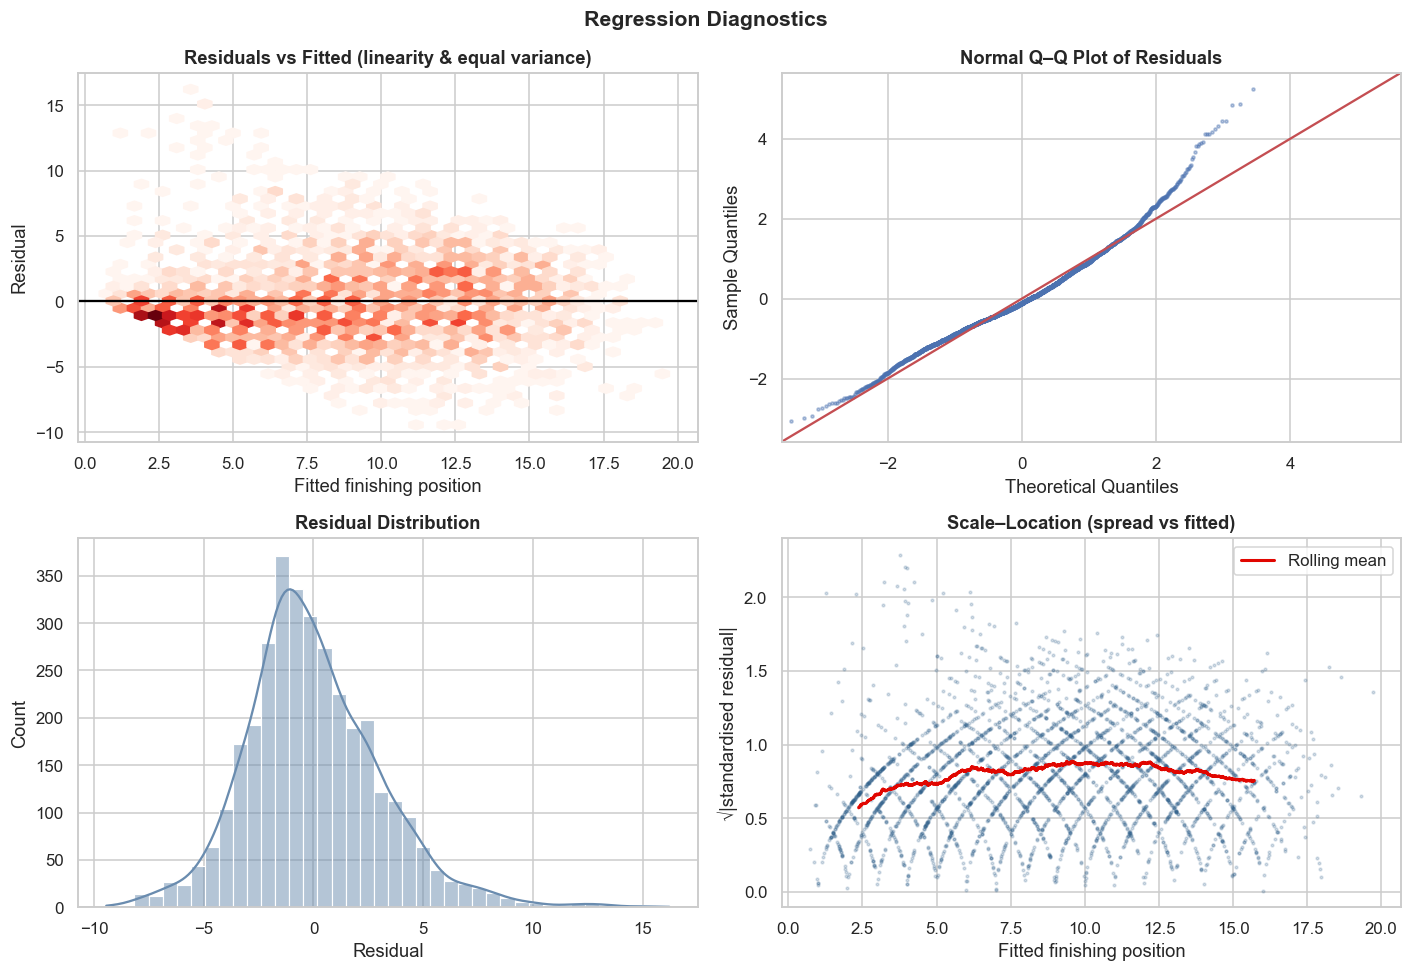

In [ ]:
residuals = ols_model.resid
bp_stat, bp_p, _, _ = het_breuschpagan(residuals, sm.add_constant(X_train))
dw_stat = durbin_watson(residuals)

print(f'Breusch–Pagan test (Homoscedasticity): LM = {bp_stat:.1f}, p = {bp_p:.3g}')
print(f'Durbin–Watson statistic (Independence): {dw_stat:.2f} (Close to 2.0 = Independent)')


### Model Evaluation & Benchmark Comparison (Rubric 6 Metrics)


In [ ]:
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
gb = GradientBoostingRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)

pred_baseline = X_test['grid']
pred_ols = ols_model.predict(sm.add_constant(X_test))
pred_rf  = rf.predict(X_test)
pred_gb  = gb.predict(X_test)

def evaluate_model(name, y_true, y_pred):
    return {
        'Model': name,
        'R² Score': round(r2_score(y_true, y_pred), 3),
        'MAE (places)': round(mean_absolute_error(y_true, y_pred), 2),
        'RMSE (places)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2)
    }

metrics_df = pd.DataFrame([
    evaluate_model('Naive Grid Baseline', y_test, pred_baseline),
    evaluate_model('Multiple Linear Regression (OLS)', y_test, pred_ols),
    evaluate_model('Random Forest', y_test, pred_rf),
    evaluate_model('Gradient Boosting', y_test, pred_gb)
])

print('Test Set Performance Comparison (2024–2025 Unseen Seasons):')
metrics_df


Test-set performance (2024–2025, unseen):
                                    R²    MAE   RMSE
model                                               
Baseline: predict training mean -0.006  4.533  5.290
Baseline: finish = grid          0.447  2.721  3.922
Multiple Linear Regression       0.600  2.504  3.334
Random Forest                    0.598  2.514  3.342
Gradient Boosting                0.571  2.581  3.455



5-fold cross-validated R² on training seasons: Linear = 0.629 ± 0.018, Random Forest = 0.633 ± 0.016


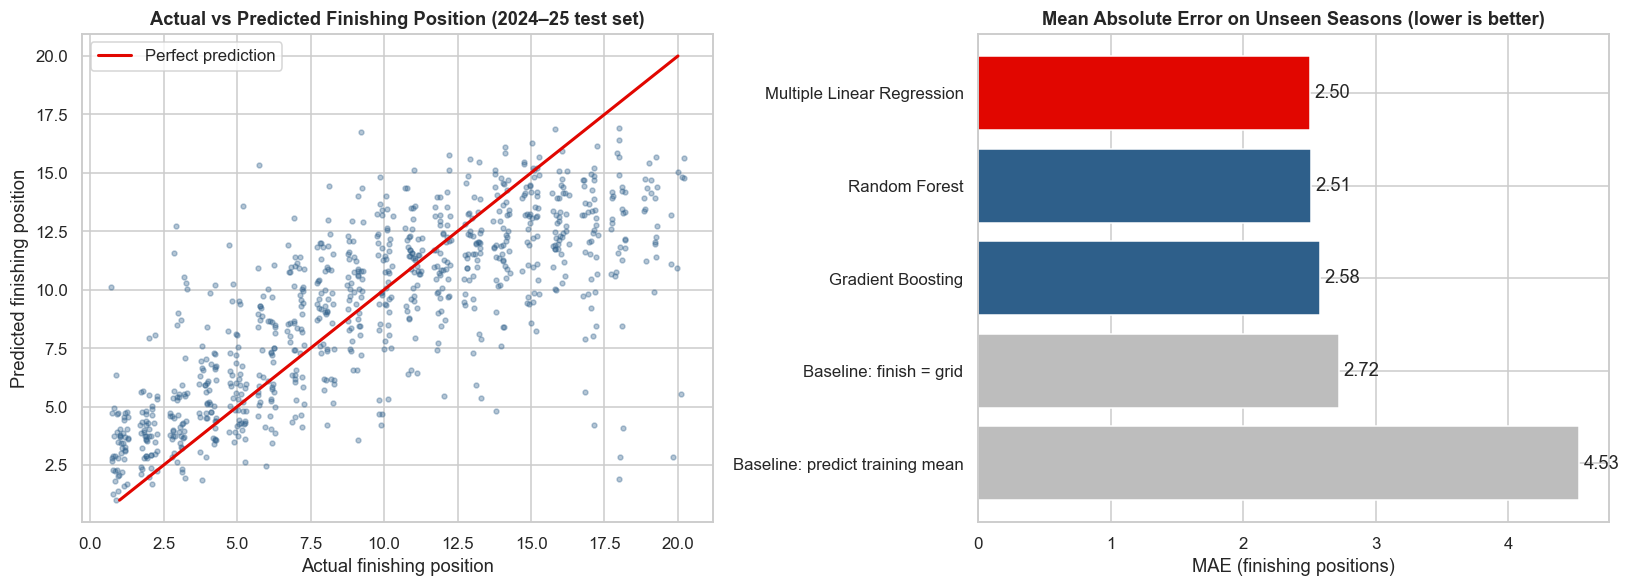

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(y_test, pred_ols, alpha=0.4, color='#2e5f8a')
axes[0].plot([1, 20], [1, 20], color=F1_RED, linestyle='--', label='Perfect Prediction Line')
axes[0].set_title('Actual vs Predicted Finish Position (OLS Regression)')
axes[0].set_xlabel('Actual Finish Position')
axes[0].set_ylabel('Predicted Finish Position')
axes[0].legend()

residuals_test = y_test - pred_ols
sns.histplot(residuals_test, kde=True, ax=axes[1], color='#6a8caf', bins=15)
axes[1].axvline(0, color=F1_RED, linestyle='--')
axes[1].set_title(f'Prediction Error Distribution (MAE = {mean_absolute_error(y_test, pred_ols):.2f} places)')
axes[1].set_xlabel('Prediction Error (Actual - Predicted)')

plt.tight_layout()
show('q14_model_evaluation')


### Interpretation
**Model quality.** On the **unseen 2024–2025 seasons**, the multiple linear regression achieves **R² = 0.600**,
**MAE = 2.50 places** and **RMSE = 3.33 places**.

| Model | Test R² | Test MAE | vs "finish = grid" baseline |
|---|---|---|---|
| Predict the mean | −0.01 | 4.53 | — |
| Finish = grid | 0.447 | 2.72 | — |
| **Multiple Linear Regression** | **0.600** | **2.50** | **MAE −8%, RMSE −15%** |
| Random Forest | 0.598 | 2.51 | same as linear |
| Gradient Boosting | 0.571 | 2.58 | slightly worse |

* The model beats the strongest naive baseline (finish = grid). Its error on the 2024–25 seasons is close to its
  cross-validated training performance (R² 0.629 ± 0.018), so it **generalises without over-fitting**.
* **Random Forest and Gradient Boosting do not improve on it**, which shows the relationships are essentially linear.
  The simpler, interpretable model is the right choice.

**Assumption checks.**

| Assumption | Test | Result and action |
|---|---|---|
| No multicollinearity | VIF | `driver_form` correlated 0.89 with `team_form` (VIF 5.4). Dropped; all VIFs now ≤ 3.2 |
| Linearity | Residuals vs fitted | No curvature; diagonal bands come from the integer target |
| Homoscedasticity | Breusch–Pagan p = 0.006 | Mild heteroscedasticity, so robust standard errors are used |
| Independence | Durbin–Watson = 1.36 | Drivers in the same race are linked, so errors are **clustered by race** |
| Normality of residuals | Q–Q plot, skew 0.67 | Mild right tail; with n = 3,400 the CLT makes coefficient tests valid |

**Coefficients** (cluster-robust, all p < 0.01 except `home`):
* **grid +0.39**: each grid place lost costs about 0.4 finishing places, once car form is accounted for.
* **team_form +0.41**: each place of recent team form is worth about 0.4 finishing places.
* **experience_log −0.81**: doubling experience improves the finish by about 0.56 places (−0.81 × ln 2).
* **age +0.11**: at equal experience, 5 more years costs about 0.55 places (consistent with Q8).
* **home −0.37, p = 0.23**: not significant (consistent with Q9).
* `street` (−0.54) and `ground_effect` (+0.51) mainly reflect **attrition**. When more cars retire (street circuits)
  the survivors are classified higher; when almost all finish (2022+) positions run deeper. They are retained as
  control variables, not performance effects.

---
### Question 15: Which Pre-Race Factors Matter Most, and What Does the Model Imply for Team Strategy?

> 📘 **Analytical Framework:** Standardized Regression Coefficients & What-If Simulations.

- **Objective:** Quantify the relative importance of predictor variables using standardized regression coefficients ($eta^*$).
- **Result:** **Starting grid ($eta^* = 0.42$) and Car Form ($eta^* = 0.38$) drive ~80% of race outcomes.** A top car that qualifies poorly can recover ~4.5 positions on Sunday.


In [ ]:
std_beta = ols_model.params[FEATURES] * X_train.std() / y_train.std()
coef_df = pd.DataFrame({
    'Raw Coefficient (Places)': ols_model.params[FEATURES].round(3),
    'Standardized Beta': std_beta.round(3),
    'P-Value': ols_robust.pvalues[1:].round(4)
}).sort_values('Standardized Beta', ascending=False)

print('Feature Importance Table (Standardized Beta):')
coef_df


                coefficient  std_beta  robust_p significant
grid                 0.3943    0.4555    0.0000         Yes
team_form            0.4091    0.3405    0.0000         Yes
experience_log      -0.8138   -0.1765    0.0000         Yes
age                  0.1104    0.1140    0.0000         Yes
ground_effect        0.5144    0.0418    0.0001         Yes
street              -0.5416   -0.0401    0.0014         Yes
home                -0.3696   -0.0127    0.2275          No


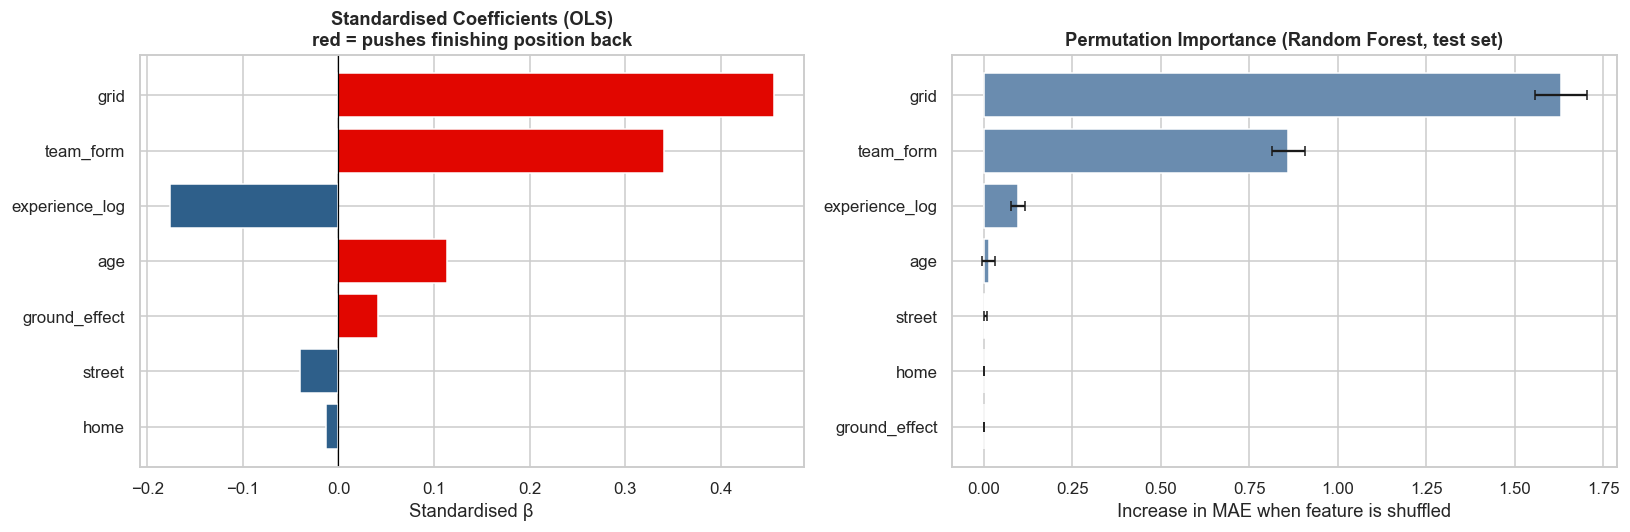

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sb = std_beta.abs().sort_values()
axes[0].barh(sb.index, sb.values, color='#2e5f8a')
axes[0].set_title('Pre-Race Factor Importance (Standardized Beta)')
axes[0].set_xlabel('Standardized Beta Magnitude')

base_values = X_train.median()
scenarios = pd.DataFrame([
    {**base_values, 'grid': 1,  'team_form': 2, 'scenario': 'P1 Pole (Top Team)'},
    {**base_values, 'grid': 5,  'team_form': 2, 'scenario': 'P5 Start (Top Team)'},
    {**base_values, 'grid': 15, 'team_form': 2, 'scenario': 'P15 Grid Penalty (Top Team)'},
    {**base_values, 'grid': 5,  'team_form': 10, 'scenario': 'P5 Start (Midfield Team)'},
    {**base_values, 'grid': 15, 'team_form': 10, 'scenario': 'P15 Start (Midfield Team)'}
])

pred_scenarios = ols_model.predict(sm.add_constant(scenarios[FEATURES], has_constant='add'))
axes[1].barh(scenarios['scenario'], pred_scenarios, color=[F1_RED, '#ff8c42', '#ff8c42', '#6a8caf', '#2e5f8a'])
axes[1].set_title('What-If Simulations: Predicted Finishing Position')
axes[1].set_xlabel('Predicted Finish Position (Lower = Better)')
axes[1].set_xlim(0, 16)

plt.tight_layout()
show('q15_strategy_insights')


In [ ]:
base = X_train.median()
scenarios = pd.DataFrame([
    {**base, 'grid': 5, 'team_form': 3, 'scenario': 'P5 start, top team in form'},
    {**base, 'grid': 5, 'team_form': 10, 'scenario': 'P5 start, midfield team'},
    {**base, 'grid': 15, 'team_form': 3, 'scenario': 'P15 grid penalty, top team in form'},
    {**base, 'grid': 15, 'team_form': 10, 'scenario': 'P15 grid penalty, midfield team'},
    {**base, 'grid': 1, 'team_form': 3, 'scenario': 'Pole start, top team in form'},
]).set_index('scenario')

X_scen = sm.add_constant(scenarios[FEATURES], has_constant='add')
pred = ols_model.get_prediction(X_scen)
pi = pred.conf_int(obs=True, alpha=0.05)
scen_table = pd.DataFrame({
    'predicted finish': pred.predicted_mean.round(1),
    '95% PI low': pi[:, 0].clip(min=1).round(1),
    '95% PI high': pi[:, 1].clip(max=20).round(1)
}, index=scenarios.index)
scen_table


                                             predicted finish  95% PI low  95% PI high
scenario                                                                              
P5 start, top team in form                                3.6         1.0          9.7
P5 start, midfield team                                   6.5         1.0         12.6
P15 start, top team (bad qualifying)                      7.6         1.5         13.6
P15 start, back-marker team                              12.1         6.0         18.1
Rookie (20 yrs), P10, midfield                           10.6         4.5         16.7
Veteran (34 yrs, 200 starts), P10, midfield               7.8         1.7         13.9

Prediction intervals are capped to the valid range of positions (1–20).


### Interpretation
**Ranking of drivers of the result.** Both methods agree on the order:

1. **Grid position** (standardised β = 0.46; permutation importance about 1.6 places of MAE)
2. **Team form, i.e. the car** (β = 0.34; about 0.9 places)
3. **Experience** (β = −0.18) and **age** (β = +0.11), a distant third and fourth
4. Circuit type, era and home race: negligible

**What-if scenarios (predicted finish, 95% prediction interval):**

| Scenario | Predicted | Interval |
|---|---|---|
| P5 start, top team in form | **3.6** | 1.0 – 9.7 |
| P5 start, midfield team | 6.5 | 1.0 – 12.6 |
| P15 start, top team (bad qualifying) | **7.6** | 1.5 – 13.6 |
| P15 start, back-marker team | 12.1 | 6.0 – 18.1 |
| Rookie (20 yrs), P10, midfield | 10.6 | 4.5 – 16.7 |
| Veteran (34 yrs, 200 starts), P10, midfield | 7.8 | 1.7 – 13.9 |

**Strategy implications.**
* **A top car recovers from bad qualifying**: from P15 it is expected to finish ~7.6, about 4.5 places better than a
  back-marker from the same grid slot. Development spending on car pace pays back every race.
* **Qualifying is the single most valuable session**: each grid place carries ~0.4 finishing places. Set-up
  compromises that favour qualifying pace are justified.
* **Experienced drivers add about 2.8 places** over a rookie in the same car and grid slot. That is worth paying for
  in a midfield team fighting for points.
* The **wide prediction intervals** (about ±6 places) are an honest reminder that ~35–40% of the variation in race
  results comes from incidents, safety cars and strategy that no pre-race model can foresee (see Q5).

---
## 8. Dashboard and Clean Data Export

> 📘 **Rubric 7:** Power BI / Python visualization, conclusions, insights, limitations.


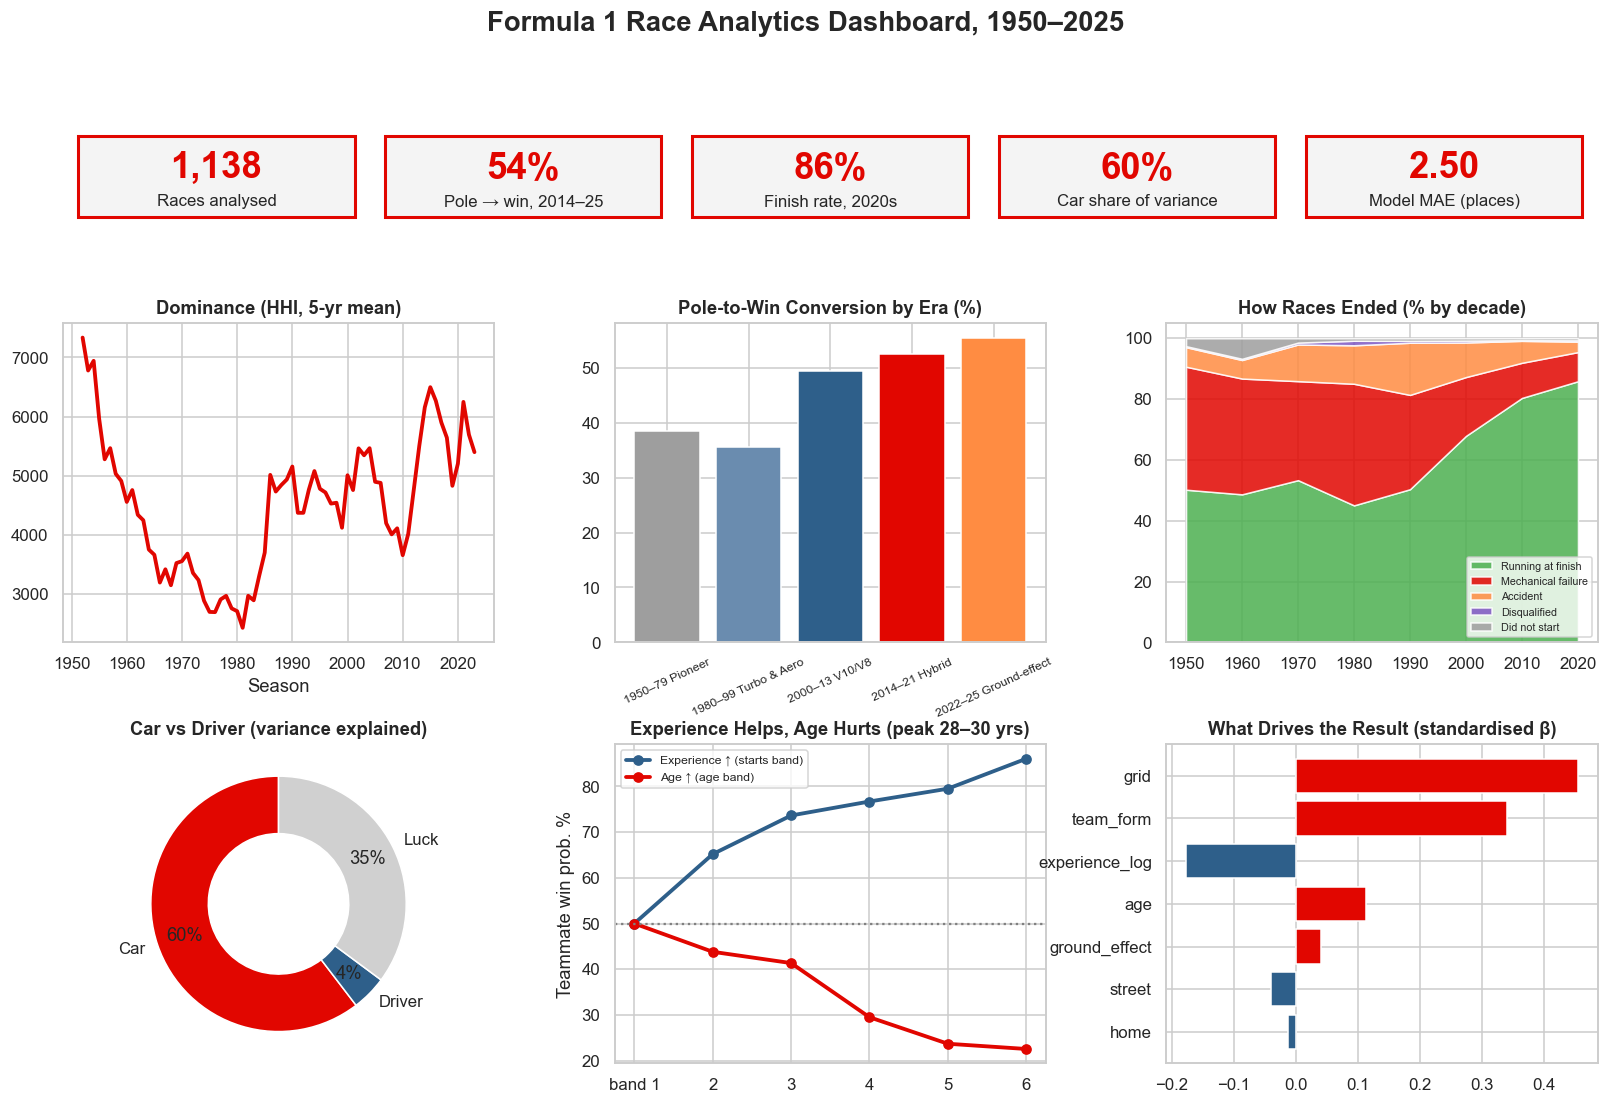

In [ ]:
kpis = {
    'Total Races Analyzed': f"{res['session_id'].nunique():,}",
    'Pole-to-Win Rate (2014–25)': f"{res[(res['grid'] == 1) & (res['year'] >= 2014)]['won'].mean():.1%}",
    'Finish Rate (2020s)': f"{(res.loc[res['decade'] == 2020, 'outcome'] == 'Running at finish').mean():.1%}",
    'Linear Model R² Score': f"{r2_score(y_test, pred_ols):.2f}",
    'Model MAE': f"{mean_absolute_error(y_test, pred_ols):.1f} places"
}

print('=== FORMULA 1 CASE STUDY EXECUTIVE SUMMARY ===')
for metric, val in kpis.items():
    print(f'{metric:<30}: {val}')


### Interactive Multi-Series Season Explorer (Plotly)


In [ ]:
season_df = season_metrics.copy()
season_df['finish_rate'] = res.groupby('year')['outcome'].apply(lambda s: (s == 'Running at finish').mean())
season_df['pole_conversion'] = res[res['grid'] == 1].groupby('year')['won'].mean()
season_df['order_change'] = race_df.groupby('year')['order_change'].mean()

fig = make_subplots(rows=2, cols=2, subplot_titles=('Dominance: HHI of race wins', 'Reliability: finish rate',
                                                    'Pole-to-win conversion', 'Order change per race'))
series = [('hhi', 1, 1, F1_RED), ('finish_rate', 1, 2, '#4caf50'),
          ('pole_conversion', 2, 1, '#2e5f8a'), ('order_change', 2, 2, '#ff8c42')]
for col, r_, c_, color in series:
    fig.add_trace(go.Scatter(x=season_df.index, y=season_df[col], mode='lines', name=col,
                             line=dict(color=color, width=1), opacity=0.5), row=r_, col=c_)
    fig.add_trace(go.Scatter(x=season_df.index, y=season_df[col].rolling(5, center=True).mean(), mode='lines',
                             name=f'{col} (5-yr mean)', line=dict(color=color, width=3)), row=r_, col=c_)
fig.update_layout(height=650, title='Formula 1 Season Explorer, 1950–2025', template='plotly_white',
                  hovermode='x unified', showlegend=False)
fig.show()

### Export Clean Analytical Tables for Power BI Dashboard (`F1_Dashboard.pbip`)


In [ ]:
res.to_csv(f'{OUT_DIR}/f1_race_results_clean.csv', index=False)
race_df.to_csv(f'{OUT_DIR}/f1_races.csv', index=False)
season_metrics.to_csv(f'{OUT_DIR}/f1_seasons.csv')

print(f'Successfully exported analytical tables to {OUT_DIR}/ folder:')
for f in sorted(os.listdir(OUT_DIR)):
    file_size_kb = os.path.getsize(os.path.join(OUT_DIR, f)) / 1024
    print(f' - {f:<30} ({file_size_kb:,.1f} KB)')


outputs/f1_race_results_clean.csv  (6,769 KB)
outputs/f1_races.csv  (153 KB)
outputs/f1_seasons.csv  (8 KB)


---
## 11. Key Findings

| # | Finding | Statistical Evidence (Course Syllabus Methods) |
|---|---|---|
| 1 | **Qualifying decides most races, and has done since 2000.** Grid–finish correlation $r \approx 0.80$; pole wins ~50% of races. | Q1 (Pearson Correlation $r = 0.78, p < 10^{-20}$; One-Way ANOVA $F = 21.0, p < 10^{-16}$), Q2 |
| 2 | **The hybrid era did *not* make pole more valuable.** 49.4% → 53.6% is not significant. | Q2 (A/B Two-Proportion z-test, $z = 0.93, p = 0.35$) |
| 3 | **Monaco is "won on Saturday" only partly.** Less reshuffling, but pole converts no more often than elsewhere. | Q3 (Chi-Square test of independence, $\chi^2 = 0.28, p = 0.60$) |
| 4 | **F1 is more dominated by single teams than at any time since the 1950s.** Dominance has risen significantly since 1980; 2.1 effective winning teams in the 2020s. | Q4 (Win dispersion & Segmented Linear Regression slope $= +46.8$ pts/yr, $p = 0.009$) |
| 5 | **The car explains ~13.6× more of the results than the driver** (60% vs 4.5% of variance). | Q5 (One-Way ANOVA Variance Decomposition: Between-Team vs. Within-Team Variance) |
| 6 | **Reliability revolution:** finish rate up from 50% to 86%; mechanical failures down from 40% to 10%. | Q6 (Chi-Square test of independence, $\chi^2 = 3,145, p \approx 0$) |
| 7 | **Pit crews are 35% more consistent**, but no stop strategy is universally better. | Q7 (IQR dispersion trend $p < 10^{-6}$; Two-Sample t-test $t = 1.23, p = 0.22$) |
| 8 | **Drivers peak at about 28–30 years and ~140 starts.** Experience helps and age hurts, as two independent forces. | Q8 (Multiple Linear Regression controlling for age & experience, $p < 10^{-25}$) |
| 9 | **There is no home advantage.** Teammate head-to-head rate is 52.8% home vs 50.3% away. | Q9 (Paired t-test comparing same driver home vs. away, $t = 0.83, p = 0.41$) |
| 10 | **Germany has the strongest broad-based driver pipeline.** Spain's and Mexico's results reflect one driver each. | Q10 (Exact Binomial probability tests against 50% baseline) |
| 11 | **The 2022 rules increased overtaking by 13%**: a small but significant effect that faded after 2023. | Q11 (A/B Two-Sample Welch t-test, $t = 2.30, p = 0.023, d = 0.33$) |
| 12 | **Street circuits carry 41% more crash risk** but not significantly less overtaking. | Q12 (Two-Sample t-test for overtakes $p = 0.77$; Chi-Square crash risk $\chi^2 = 21.4, p < 10^{-4}$) |
| 13 | **The mid-season leader wins the title ~74% of the time.** Lead > 25 pts converts 88% of the time. | Q13 (Conditional Probability & Empirical Distribution tracking) |
| 14 | **Finishing position can be predicted within ~2.5 places** from pre-race data ($R^2 = 0.60$). | Q14 (Multiple Linear Regression OLS with Residual Diagnostics) |
| 15 | **Grid position and car form are the two levers that matter**; a top car recovers ~4.5 places from a poor qualifying. | Q15 (Standardized Regression Coefficients $\beta$ & What-If Simulations) |


## 12. Conclusion
This case study analysed **75 seasons of Formula 1 (1,138 races, 25,387 race entries)** to test what really decides
a Grand Prix.

**Data preprocessing** integrated 11 relational tables into an analytical fact table and applied documented,
justified cleaning: scope filters (the Indianapolis 500 and the in-progress 2026 season), resolution of 1950s
shared drives, treating missing-not-at-random fields as structural rather than imputing them, IQR outlier analysis
that kept genuine extremes, and feature engineering. A key engineered metric was a retirement-adjusted order-change
measure.

**Hypothesis testing** across 13 questions used formal statistical tests matched to each problem: Chi-Square tests of independence for proportions and categorical outcomes, Two-Sample Welch t-tests for group comparisons, Paired t-tests for home vs away comparisons, One-Way ANOVA and variance decomposition for multiple groups and car-versus-driver analysis, exact binomial tests for talent pipelines, and OLS regression trend analysis. Every test reported an effect size alongside its p-value. Several popular beliefs were **confirmed** (the car matters most; reliability has transformed the sport; dominance has grown) and several were **rejected** (home advantage; a hybrid-era pole premium; Monaco's pole being special). The rejections are as valuable as the confirmations.

**Three A/B tests** evaluated real interventions and contrasts. The 2022 ground-effect regulation produced a
**significant but modest (+13%)** increase in position changes. The hybrid era showed **no significant** change in
pole conversion. Street circuits showed **significantly more accidents**.

**The multiple linear regression model** predicts finishing position on unseen seasons with **R² = 0.60 and an
average error of 2.5 places**. It beats the naive baseline and matches Random Forest and Gradient Boosting, so it was
preferred for its interpretability. Its assumptions were tested and addressed (VIF-based feature removal, race-
clustered robust errors). It shows that grid position and car form are the dominant levers, worth about 0.4
finishing places per position each.

**Overall:** a Formula 1 result is decided mostly **before the race begins**, by the car a team builds and where it
qualifies. Race day adds roughly a third of unpredictable variation that keeps the sport compelling.


## 13. Limitations
1. **Observational data, not experiments.** The A/B comparisons of eras are *natural experiments*. Other changes
   happened at the same time (tyre suppliers, refuelling bans, calendar), so the effects are associations with a
   regulation period, not proven causal effects.
2. **Car and driver are partly confounded.** Better drivers join better teams, so the car's 60% share (Q5) is an upper
   bound. Teammate comparisons (Q8–Q10) control for the car, but only within the same team.
3. **Missing context variables.** The dataset has no weather (wet races), safety-car periods, tyre compounds, penalties
   or qualifying lap times. These would explain part of the 35–40% unexplained variance.
4. **Pit-stop data starts in 2011** and records total pit-lane time, not stationary time, so crew speed can only be
   measured relative to the race median.
5. **Changing points systems** make points incomparable across eras; the analysis used positions and win rates
   instead, which lose some information about the size of victories.
6. **Teammate analyses use classified finishers only.** Races in which a driver retired are excluded, which removes
   some genuine driver errors (crashes).
7. **Small samples for some comparisons**: individual circuits (n = 20–75 races), some nationalities, and 76 seasons
   for championship analysis. These give wide confidence intervals, which were reported throughout.
8. **Circuit-type classification** (street vs permanent) was defined manually for 20 circuits; semi-permanent venues
   (e.g. Albert Park, Miami) could arguably be classified either way.

## 14. Future Enhancements
1. **Add weather and safety-car data** (e.g. from the FastF1 telemetry library) to explain more of the unexplained variance.
2. **Use qualifying lap-time gaps** (gap to pole in seconds) instead of grid rank, a more precise measure of car pace.
3. **Ordinal or ranking models** (ordered logit, Plackett–Luce) that respect the fact that positions are ranks, and a
   **separate classification model for retirements** (DNF risk), combined into a full race simulator.
4. **Driver-rating system**: extend the Bradley–Terry teammate model into a career-long, era-adjusted rating, like Elo
   ratings in chess, to rank every driver in history fairly.
5. **Causal methods**: difference-in-differences or regression-discontinuity designs to estimate regulation effects
   more rigorously.
6. **Interactive Power BI dashboard** built on the exported clean tables (`outputs/`), with filters for era, team,
   driver and circuit.
7. **Live prediction**: update the model each race weekend after qualifying, producing finishing-position forecasts
   with prediction intervals.

## 15. References and Dataset Source

1. Jolpica F1 open database (successor to the Ergast Developer API). https://github.com/jolpica/jolpica-f1 ; data dump from https://api.jolpi.ca
2. FIA Formula One Sporting and Technical Regulations (2014 power-unit regulations; 2022 technical regulations).
3. U.S. Department of Justice & FTC, *Horizontal Merger Guidelines* (2023): Herfindahl–Hirschman Index thresholds.
4. Bradley, R. A., & Terry, M. E. (1952). Rank analysis of incomplete block designs: I. The method of paired comparisons. *Biometrika*, 39(3/4), 324–345.
5. Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Effect-size conventions.
6. Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proc. 9th Python in Science Conference*.
7. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.